<a href="https://www.kaggle.com/code/lalit7881/instagram-influencers-eda-100?scriptVersionId=363065942" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/beamhonor0911/global-instagram-influencers-analytics-2026/instagram_global_influencers_2026.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/beamhonor0911/global-instagram-influencers-analytics-2026/instagram_global_influencers_2026.csv")

In [3]:
df.head()

,rank,channel_info,influence_score,posts,followers,avg_likes,60_day_eng_rate,new_post_avg_likes,total_likes,country,category
0,1,cristiano,98,3782,680000000,12800000,1.89,14200000,48400000000,Portugal,Sports
1,2,leomessi,97,1204,517000000,14300000,2.77,16100000,17200000000,Argentina,Sports
2,3,selenagomez,96,1935,403000000,8700000,2.16,9400000,16800000000,United States,Music/Entertainment
3,4,therock,95,7842,381000000,4200000,1.10,4800000,32900000000,United States,Entertainment/Fitness
4,5,kyliejenner,94,7216,380000000,7500000,1.97,8100000,54100000000,United States,Fashion/Business


In [4]:
df.tail()

,rank,channel_info,influence_score,posts,followers,avg_likes,60_day_eng_rate,new_post_avg_likes,total_likes,country,category
95,96,sachintendulkar,34,3824,43800000,620000,1.42,680000,2370000000,India,Sports/Cricket
96,97,kaikigreene,33,4216,8400000,480000,5.71,530000,2020000000,United States,Fitness/Wellness
97,98,bellapoarch,32,624,33400000,2800000,8.38,3100000,1750000000,Philippines/United States,Content Creator
98,99,soheeart,31,2418,18600000,520000,2.80,580000,1260000000,South Korea,Art/Design
99,100,taborel_creates,30,1424,16800000,420000,2.50,460000,598000000,Nigeria,Content Creator


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   rank                100 non-null    int64  
 1   channel_info        100 non-null    object 
 2   influence_score     100 non-null    int64  
 3   posts               100 non-null    int64  
 4   followers           100 non-null    int64  
 5   avg_likes           100 non-null    int64  
 6   60_day_eng_rate     100 non-null    float64
 7   new_post_avg_likes  100 non-null    int64  
 8   total_likes         100 non-null    int64  
 9   country             100 non-null    object 
 10  category            100 non-null    object 
dtypes: float64(1), int64(7), object(3)
memory usage: 8.7+ KB


In [6]:
df.describe()

,rank,influence_score,posts,followers,avg_likes,60_day_eng_rate,new_post_avg_likes,total_likes
count,100.000000,100.00000,100.000000,1.000000e+02,1.000000e+02,100.000000,1.000000e+02,1.000000e+02
mean,50.500000,63.54000,6215.380000,1.257040e+08,2.820400e+06,2.959800,3.084600e+06,9.503970e+09
std,29.011492,17.79253,11524.370736,1.176260e+08,2.562349e+06,2.421709,2.808254e+06,1.070980e+10
min,1.000000,30.00000,318.000000,4.800000e+06,1.800000e+05,0.300000,2.100000e+05,1.430000e+08
25%,25.750000,50.00000,1178.500000,5.300000e+07,8.775000e+05,1.270000,9.550000e+05,2.357500e+09
50%,50.500000,63.00000,2846.500000,7.980000e+07,2.100000e+06,2.075000,2.300000e+06,4.895000e+09
75%,75.250000,77.00000,5400.250000,1.557500e+08,4.200000e+06,4.160000,4.600000e+06,1.225000e+10
max,100.000000,98.00000,82416.000000,6.800000e+08,1.430000e+07,11.970000,1.610000e+07,5.410000e+10


In [7]:
df.isnull().sum()

rank                  0
channel_info          0
influence_score       0
posts                 0
followers             0
avg_likes             0
60_day_eng_rate       0
new_post_avg_likes    0
total_likes           0
country               0
category              0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

rank                    int64
channel_info           object
influence_score         int64
posts                   int64
followers               int64
avg_likes               int64
60_day_eng_rate       float64
new_post_avg_likes      int64
total_likes             int64
country                object
category               object
dtype: object

In [10]:
df.shape

(100, 11)

In [11]:
df.nunique()

rank                  100
channel_info          100
influence_score        68
posts                  85
followers              95
avg_likes              50
60_day_eng_rate        87
new_post_avg_likes     56
total_likes            95
country                24
category               37
dtype: int64

In [12]:
df.columns

Index(['rank', 'channel_info', 'influence_score', 'posts', 'followers',
       'avg_likes', '60_day_eng_rate', 'new_post_avg_likes', 'total_likes',
       'country', 'category'],
      dtype='object')

## EDA

Dataset Shape: (100, 11)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   rank                100 non-null    int64  
 1   channel_info        100 non-null    object 
 2   influence_score     100 non-null    int64  
 3   posts               100 non-null    int64  
 4   followers           100 non-null    int64  
 5   avg_likes           100 non-null    int64  
 6   60_day_eng_rate     100 non-null    float64
 7   new_post_avg_likes  100 non-null    int64  
 8   total_likes         100 non-null    int64  
 9   country             100 non-null    object 
 10  category            100 non-null    object 
dtypes: float64(1), int64(7), object(3)
memory usage: 8.7+ KB

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
rank,100.0,5.050000e+01,2.901149e+01,1.0,2.575000e+01,5.050000e+01,7.525000e+01,1.000000e+02
influence_score,100.0,6.354000e+01,1.779253e+01,30.0,5.000000e+01,6.300000e+01,7.700000e+01,9.800000e+01
posts,100.0,6.215380e+03,1.152437e+04,318.0,1.178500e+03,2.846500e+03,5.400250e+03,8.241600e+04
followers,100.0,1.257040e+08,1.176260e+08,4800000.0,5.300000e+07,7.980000e+07,1.557500e+08,6.800000e+08
avg_likes,100.0,2.820400e+06,2.562349e+06,180000.0,8.775000e+05,2.100000e+06,4.200000e+06,1.430000e+07
60_day_eng_rate,100.0,2.959800e+00,2.421709e+00,0.3,1.270000e+00,2.075000e+00,4.160000e+00,1.197000e+01
new_post_avg_likes,100.0,3.084600e+06,2.808254e+06,210000.0,9.550000e+05,2.300000e+06,4.600000e+06,1.610000e+07
total_likes,100.0,9.503970e+09,1.070980e+10,143000000.0,2.357500e+09,4.895000e+09,1.225000e+10,5.410000e+10



Missing Values:
rank                  0
channel_info          0
influence_score       0
posts                 0
followers             0
avg_likes             0
60_day_eng_rate       0
new_post_avg_likes    0
total_likes           0
country               0
category              0
dtype: int64


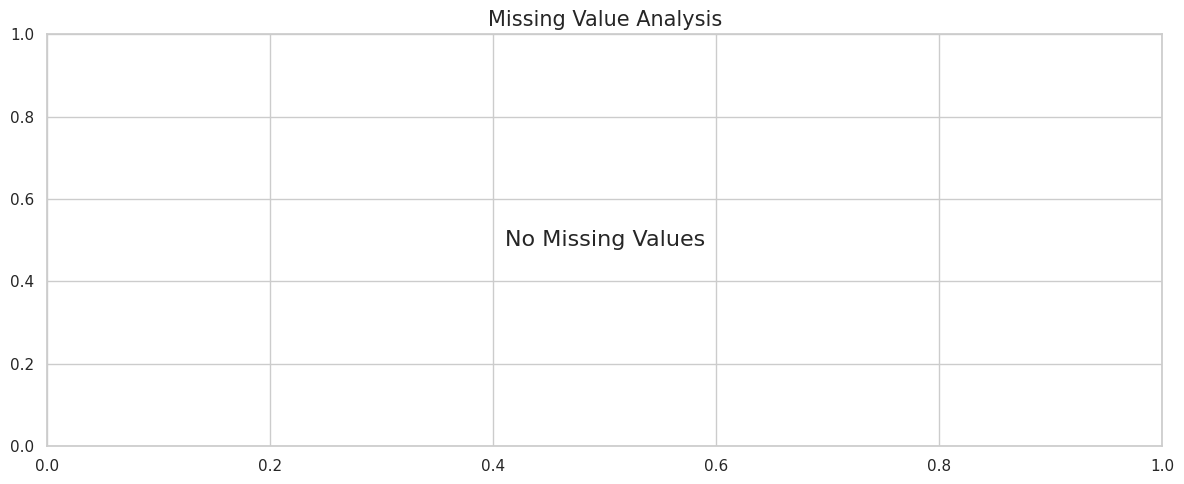

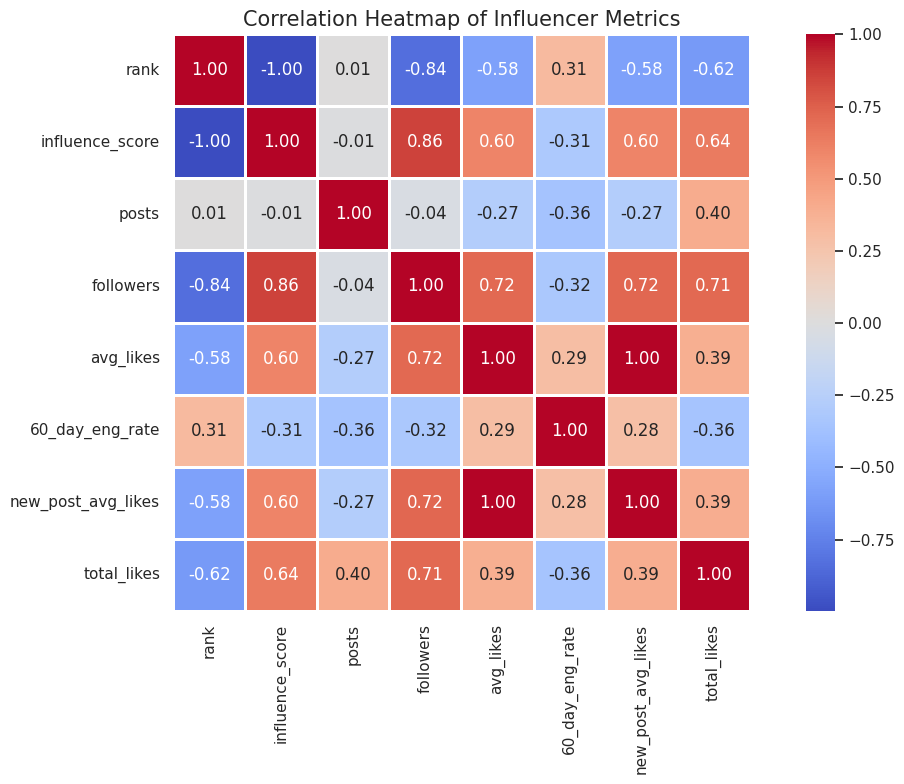

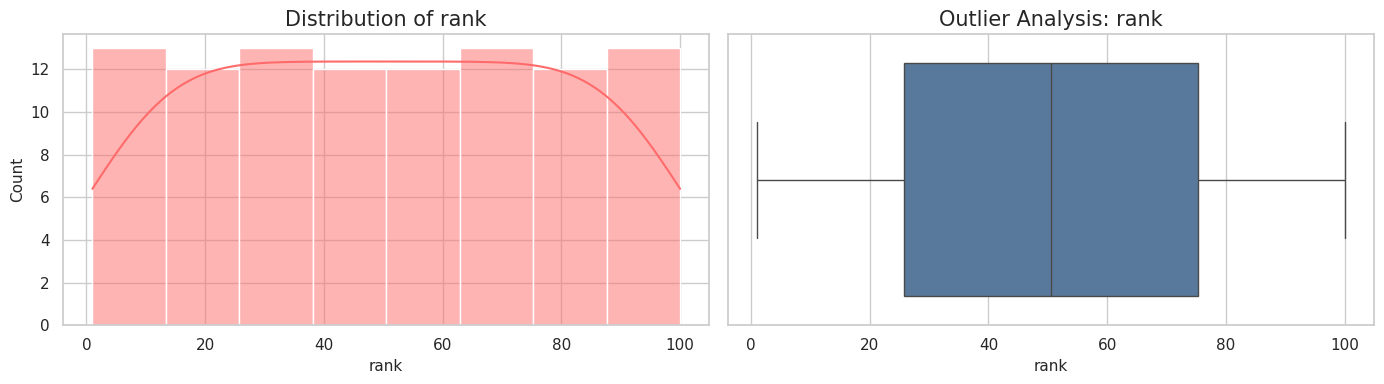

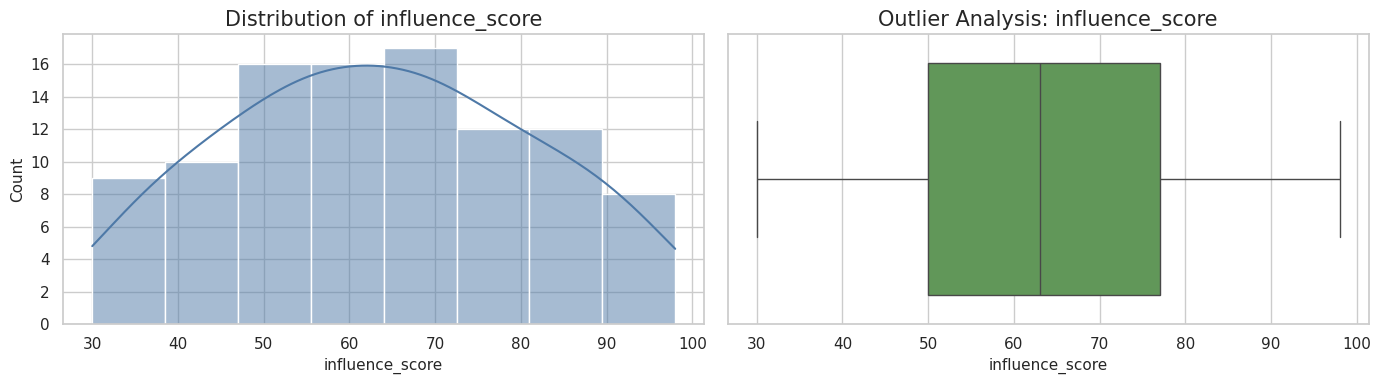

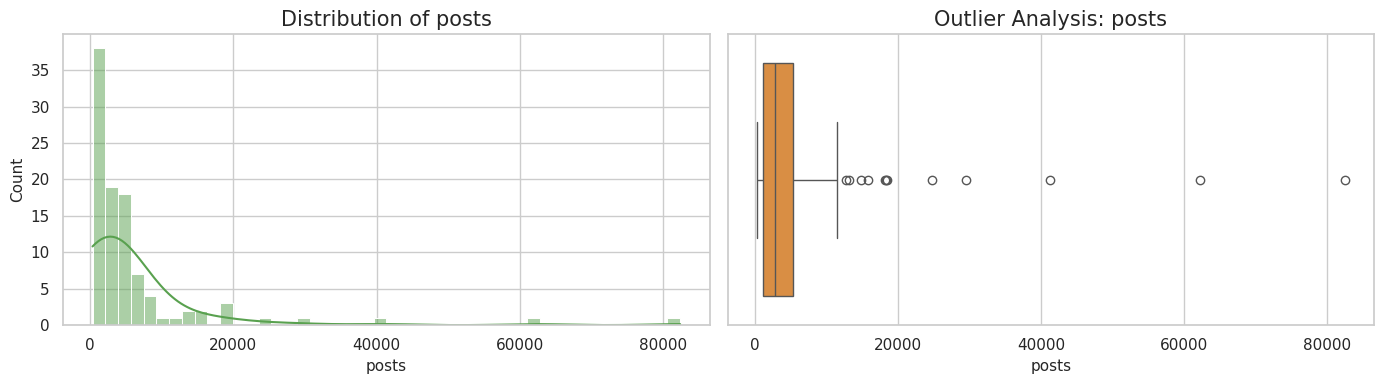

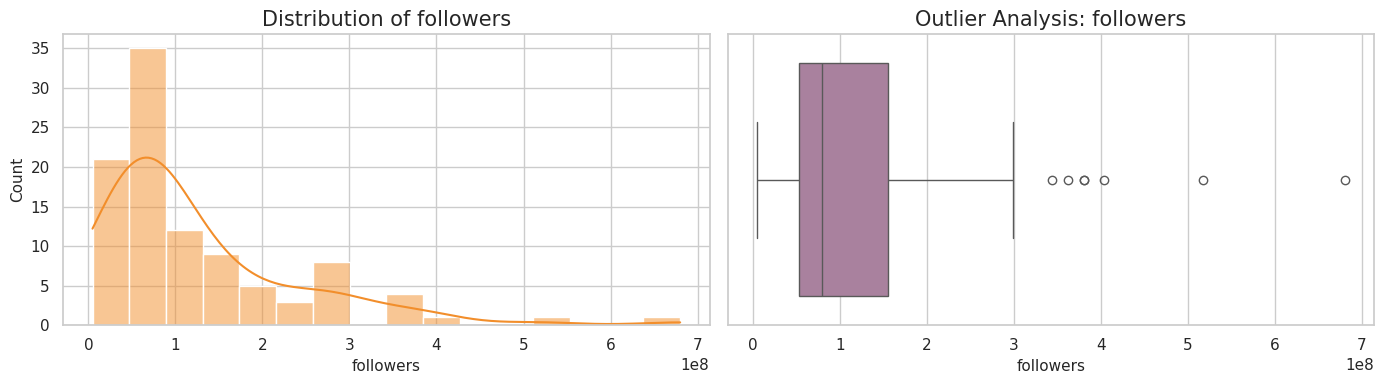

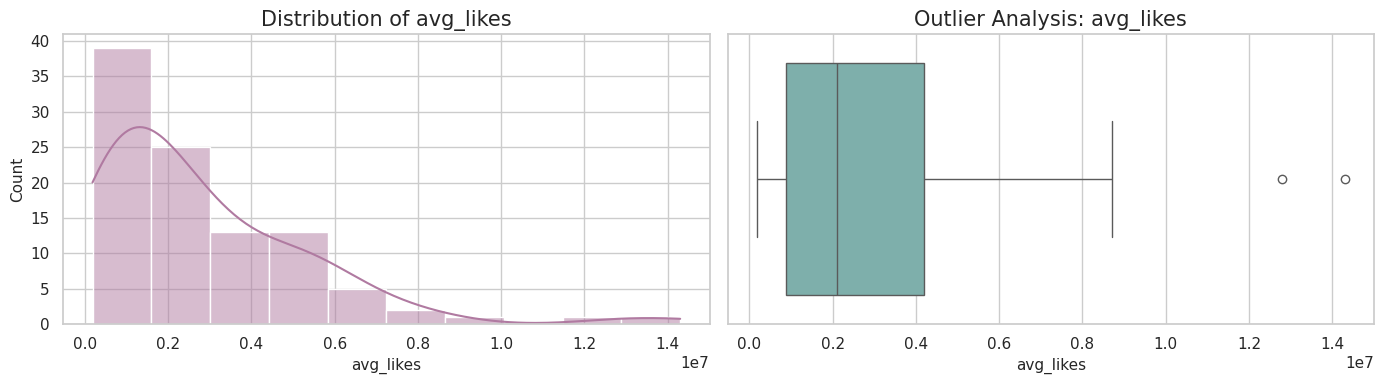

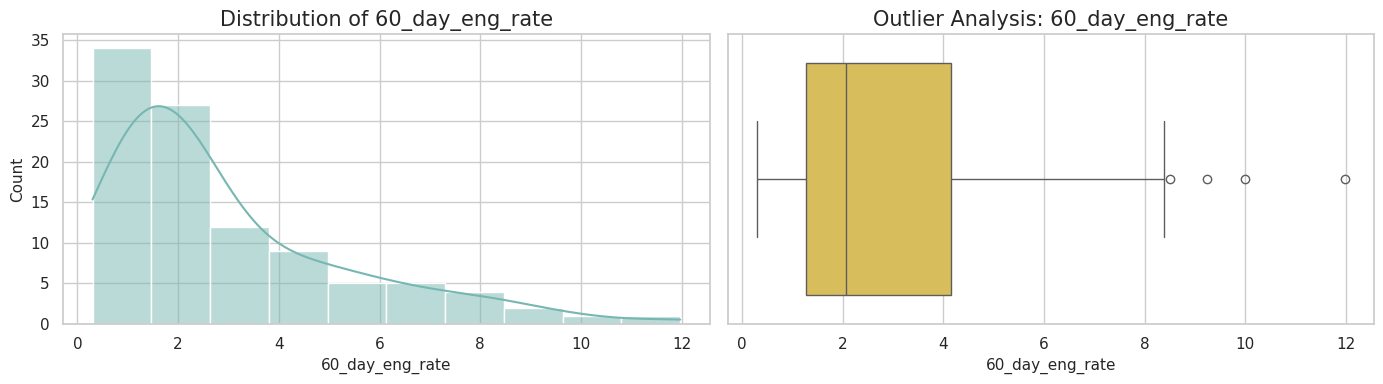

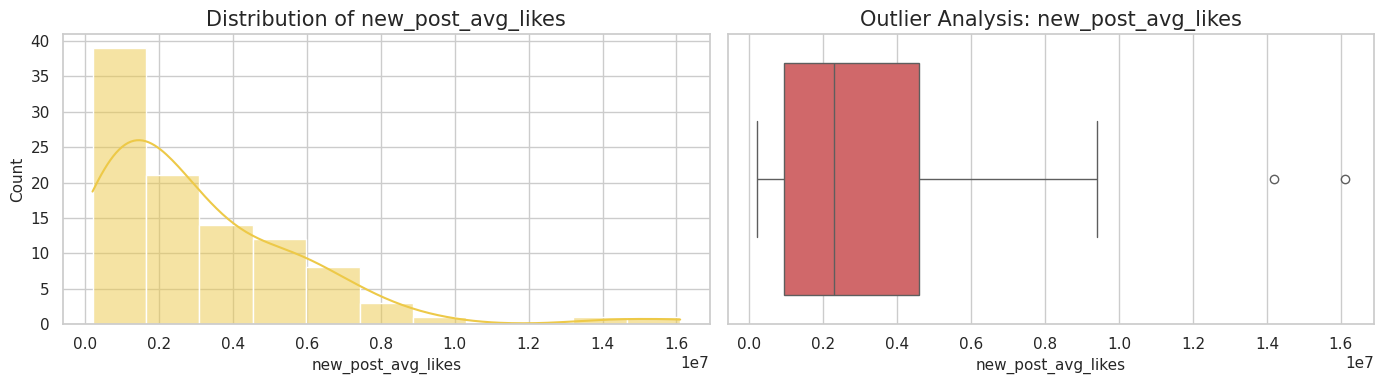

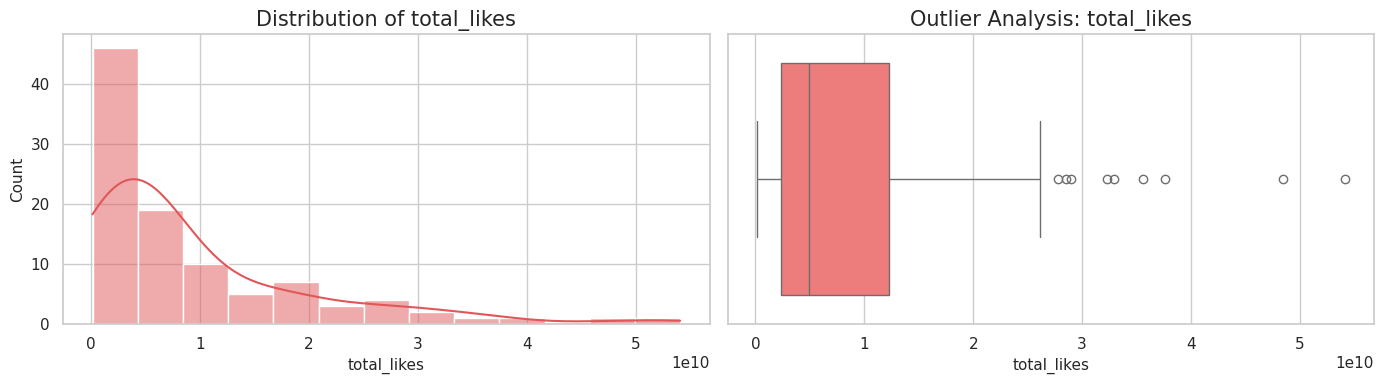

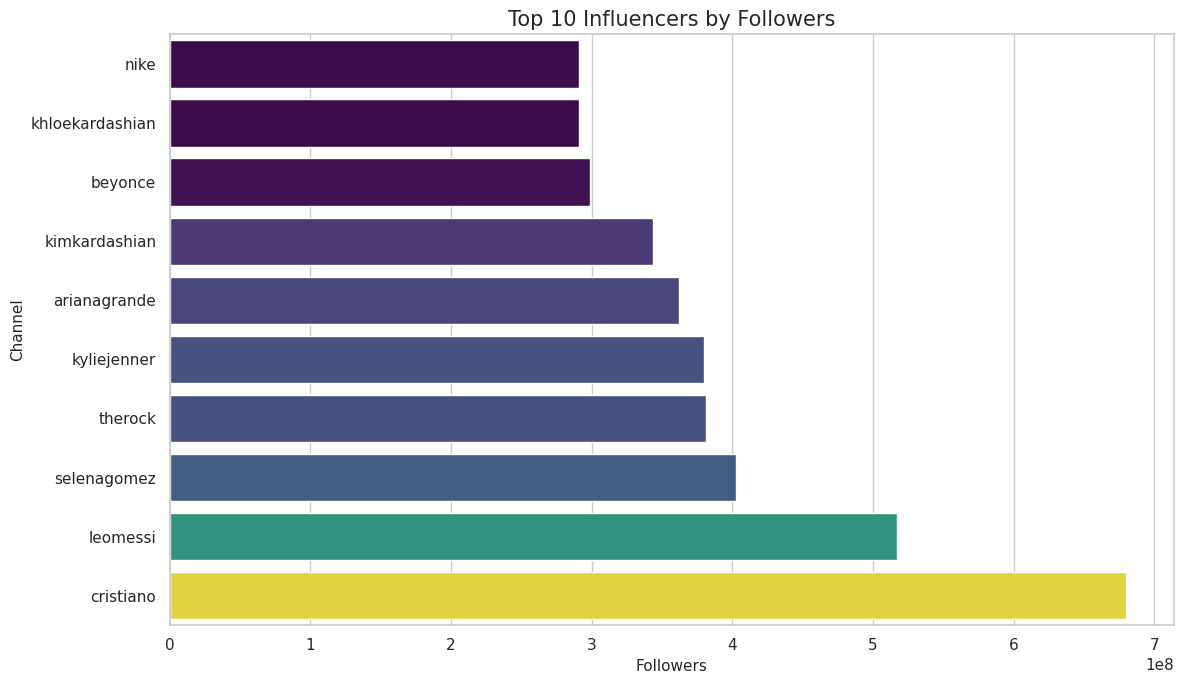

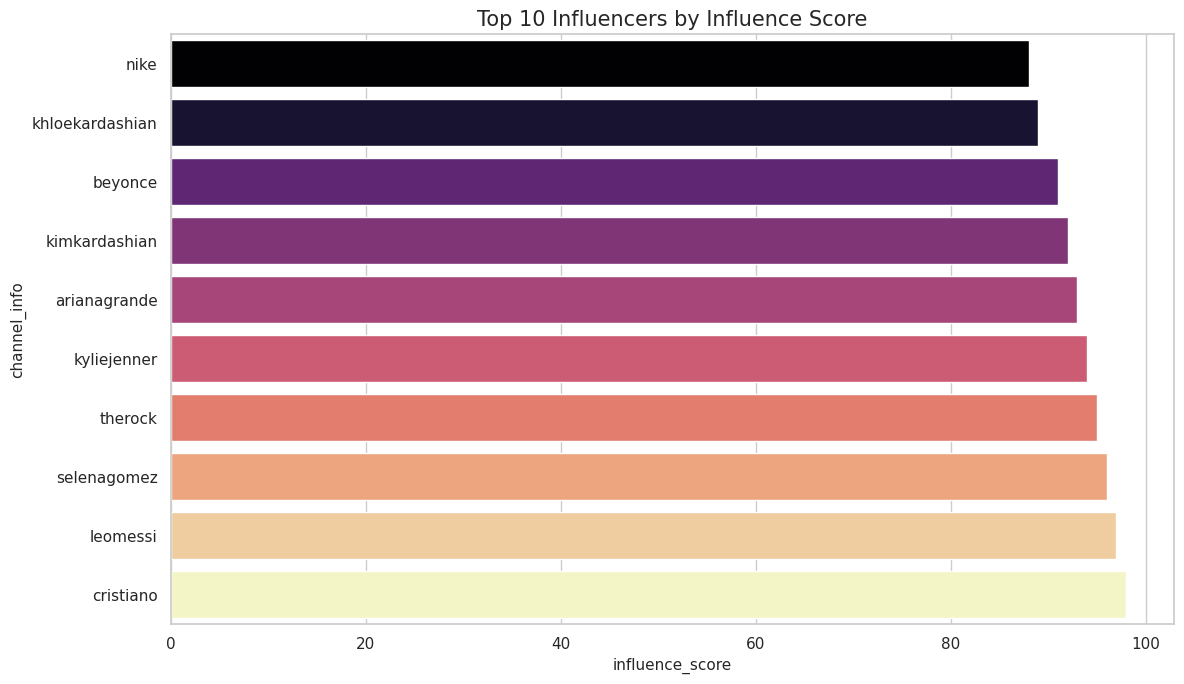

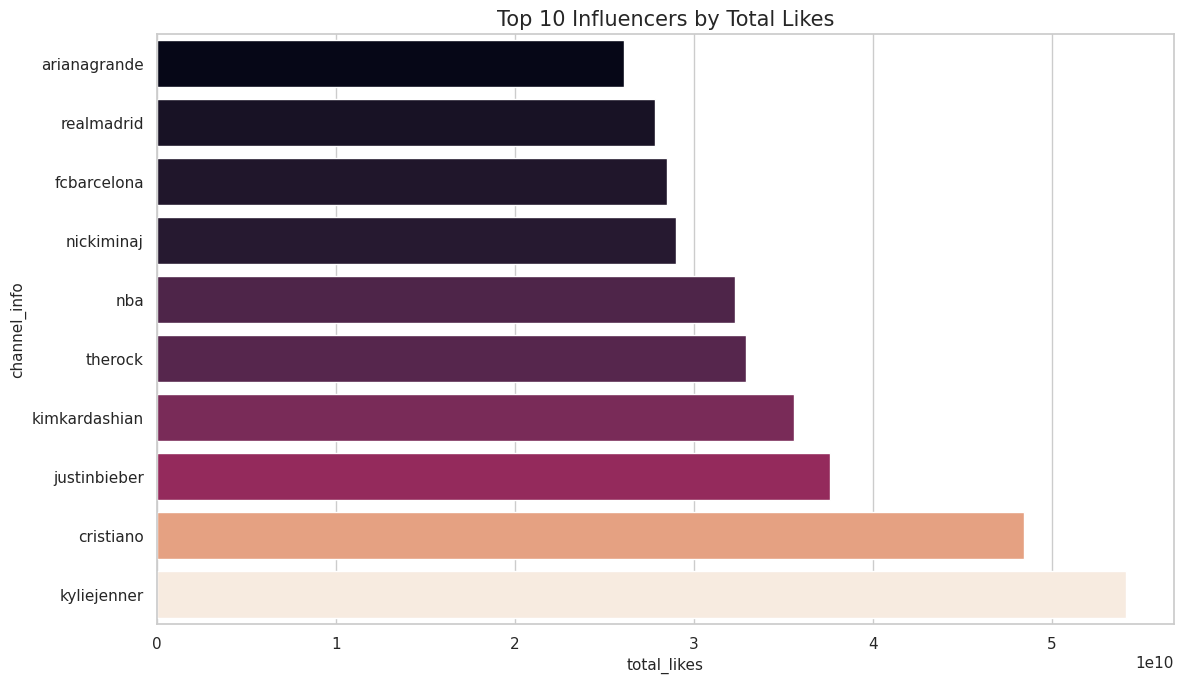

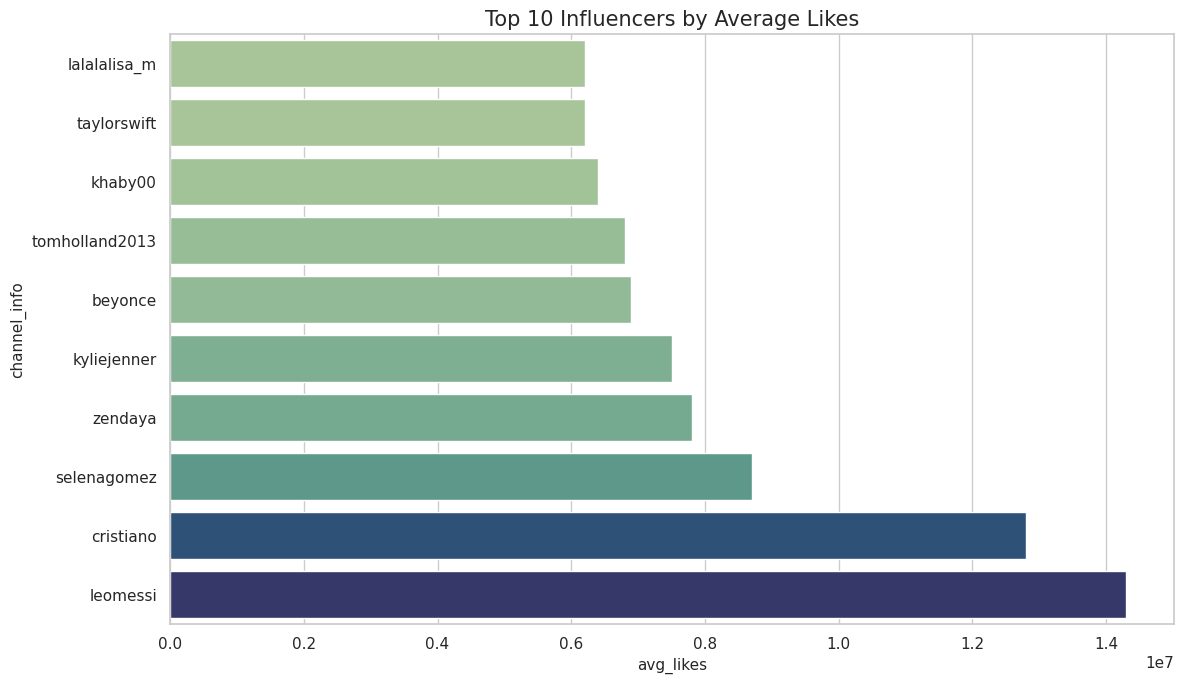

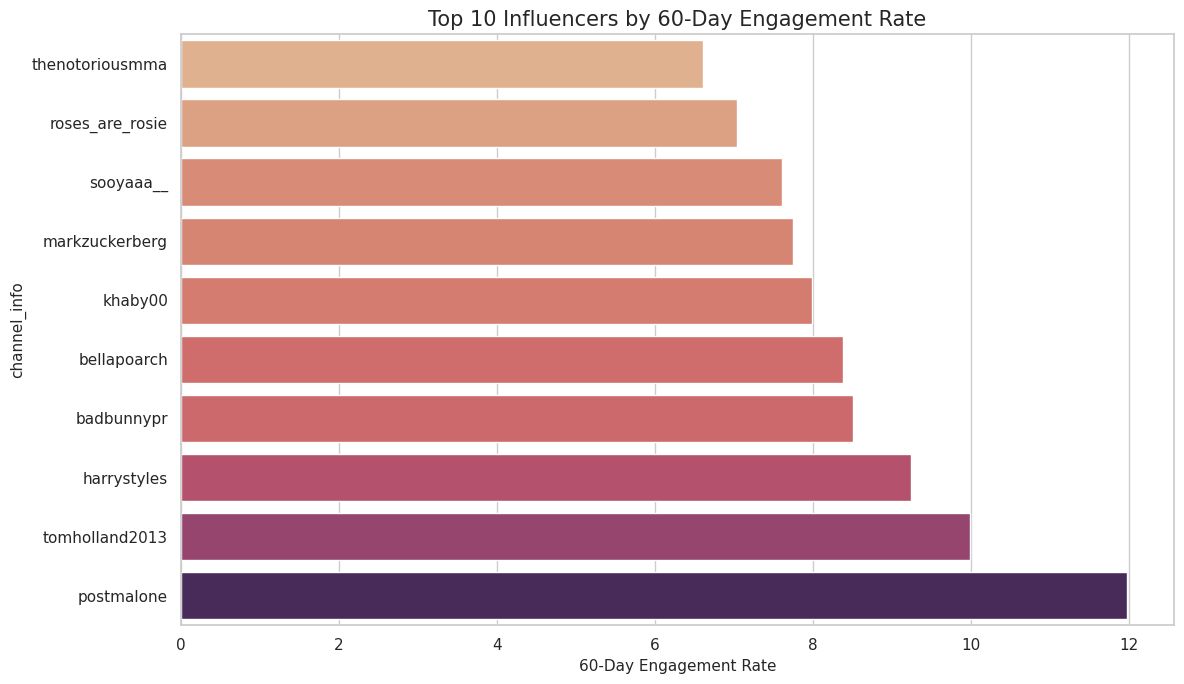

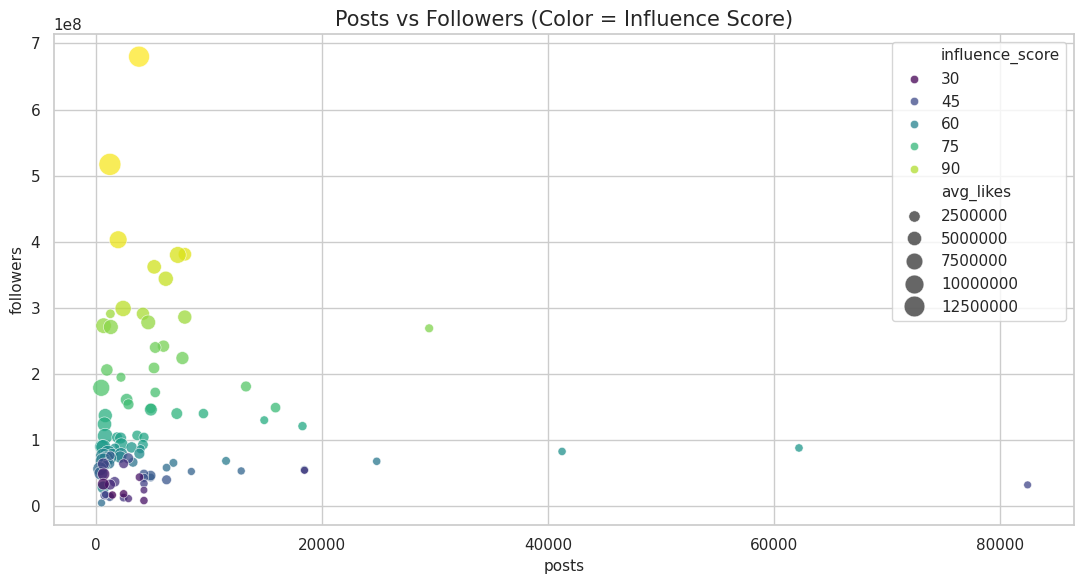

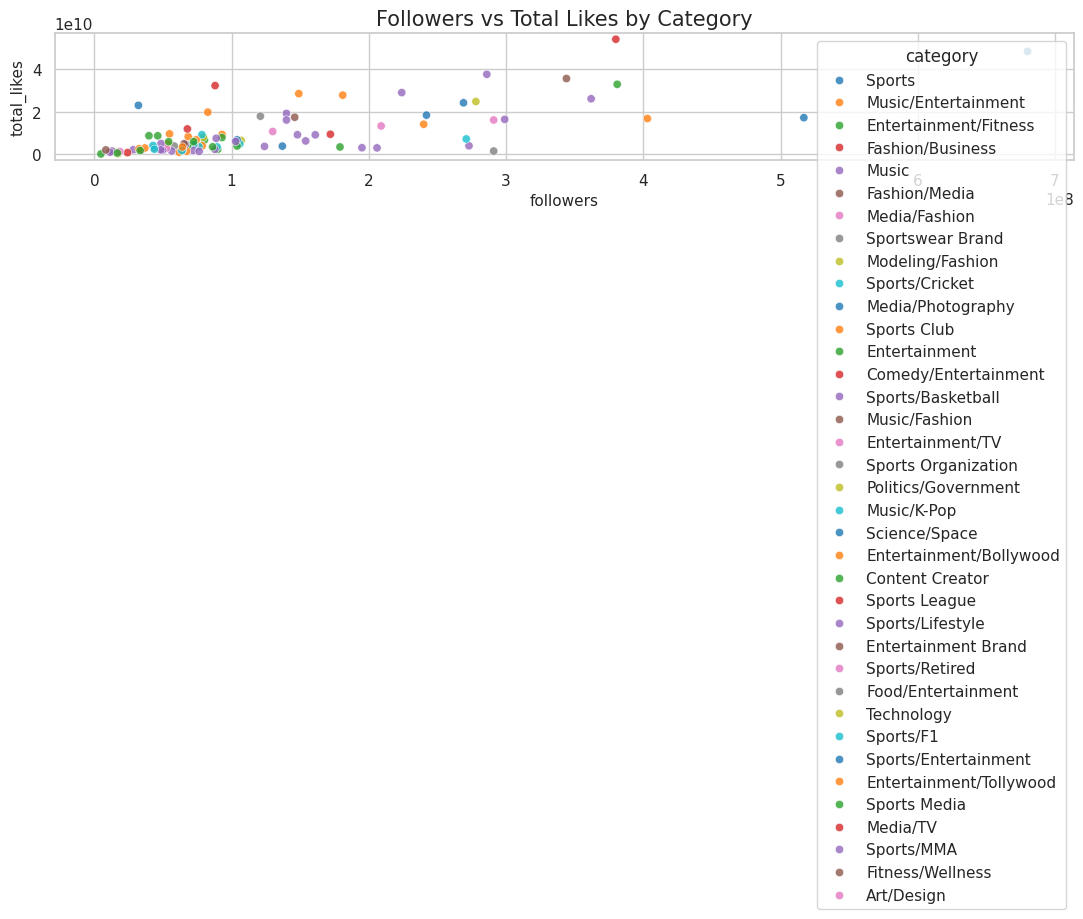

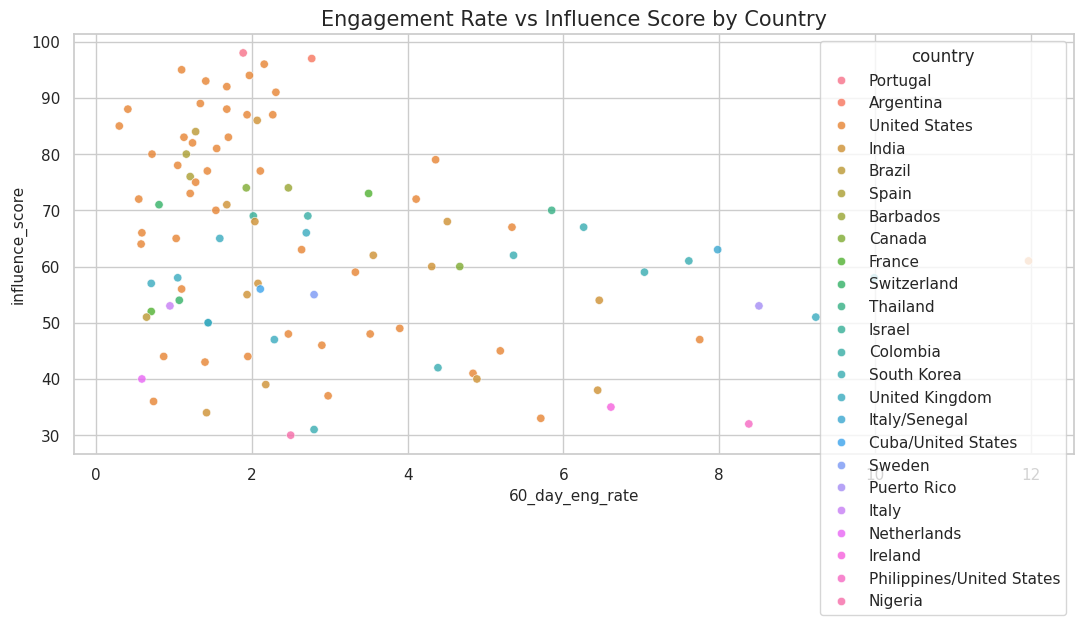

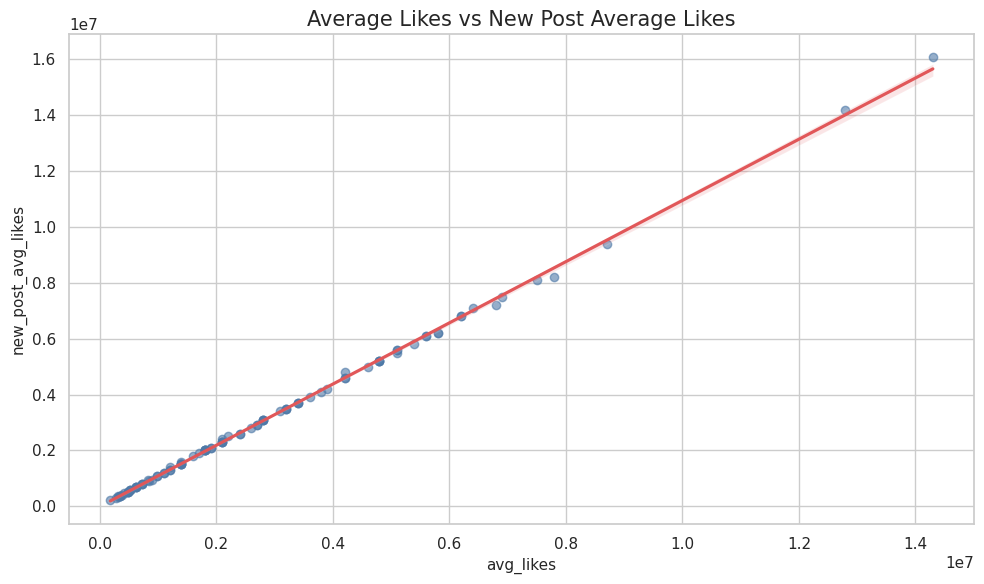

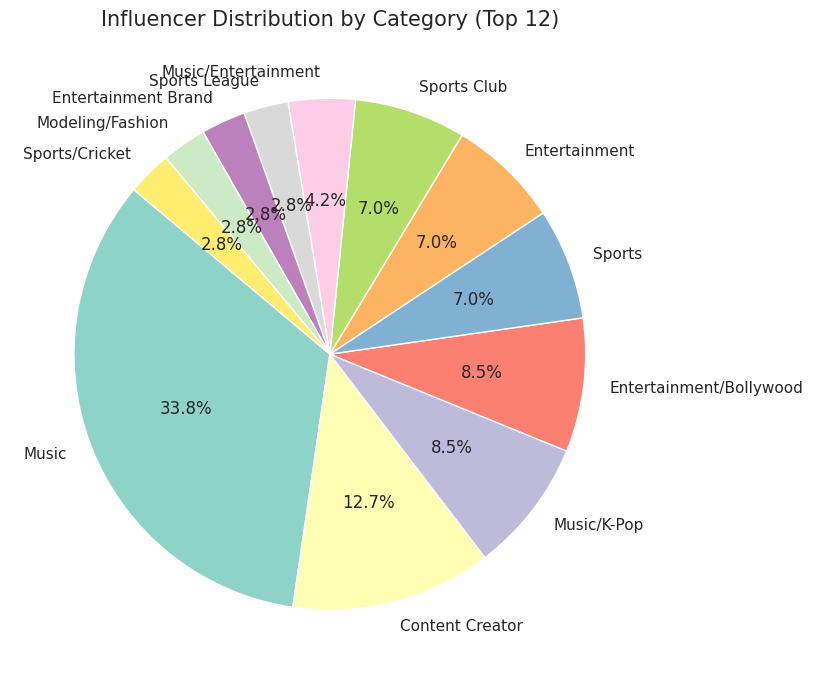

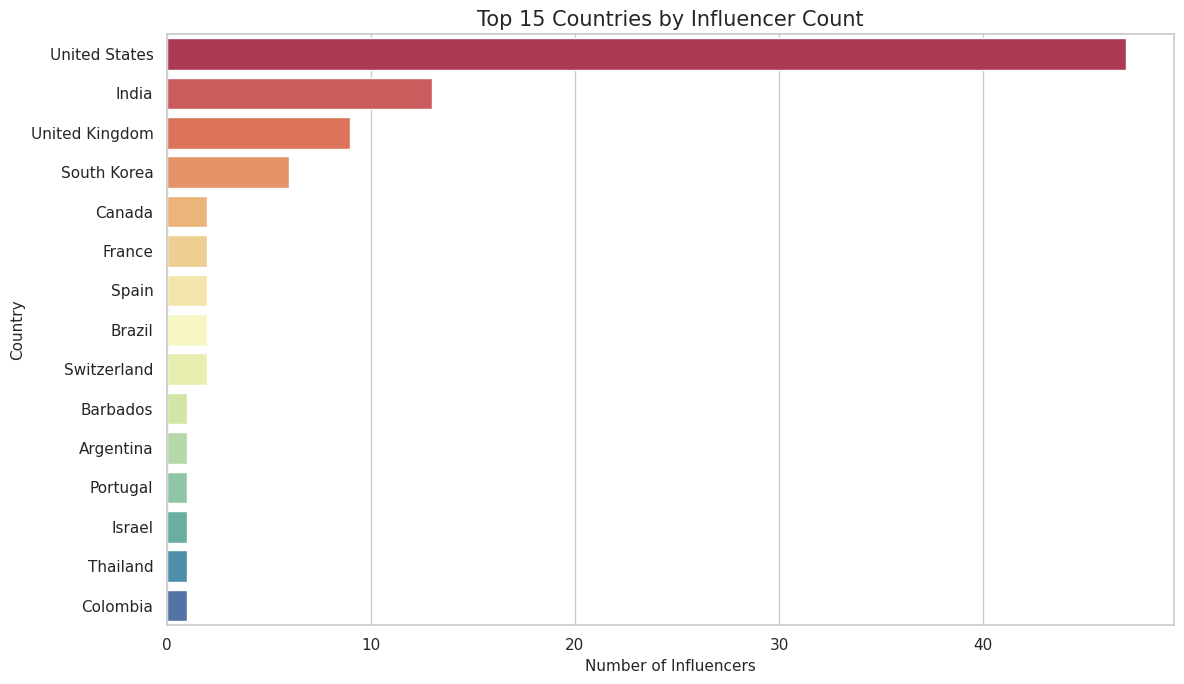

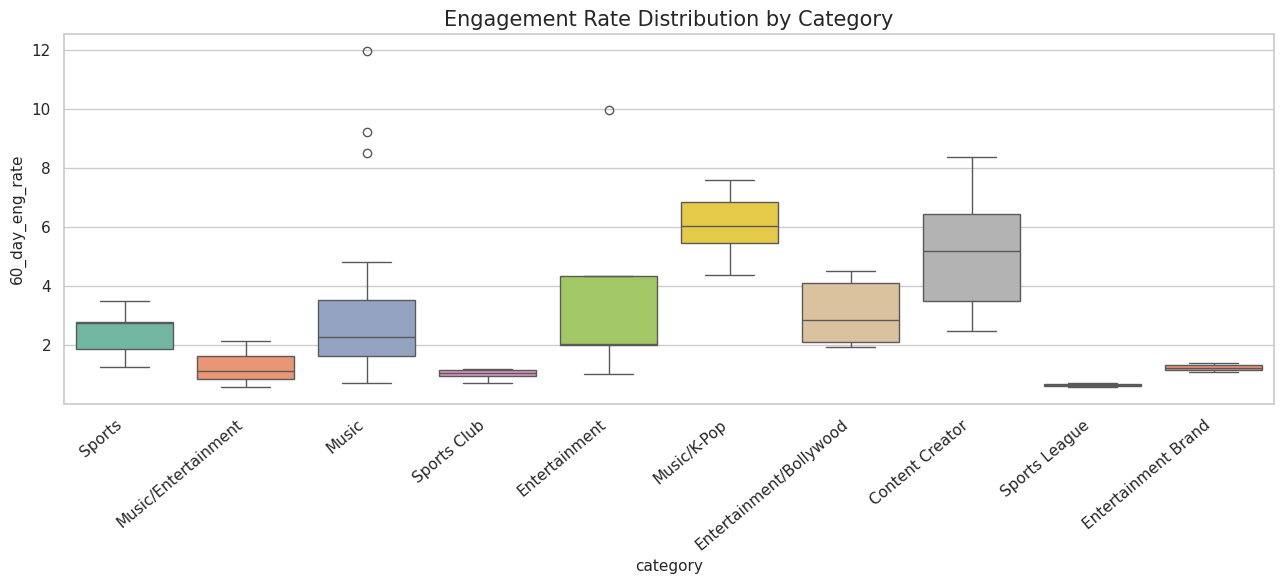

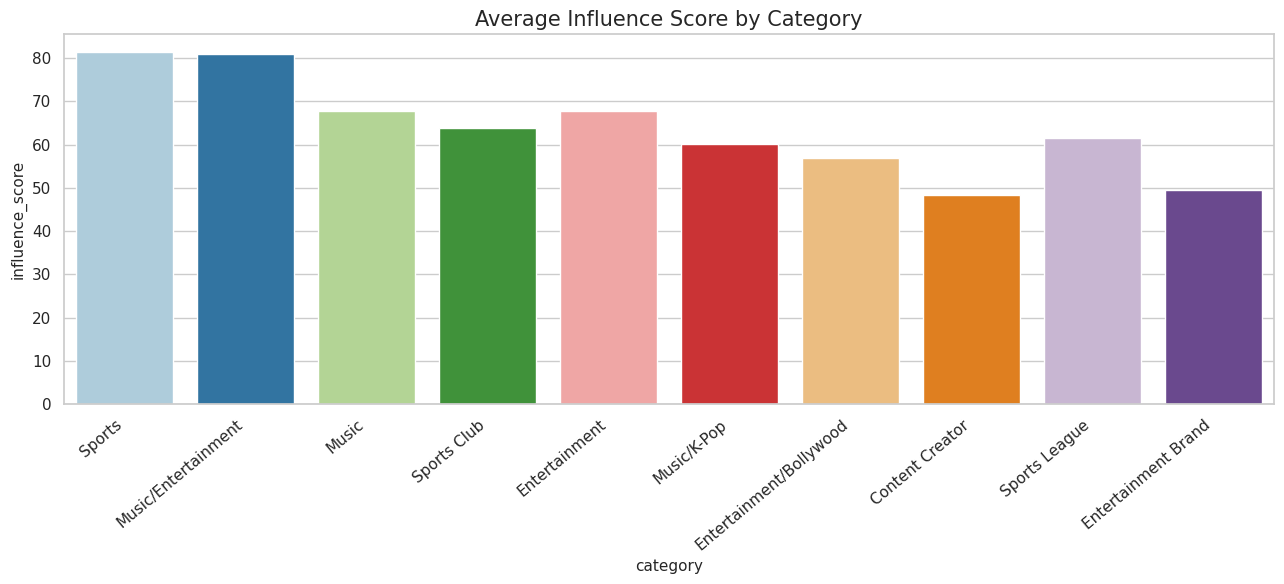

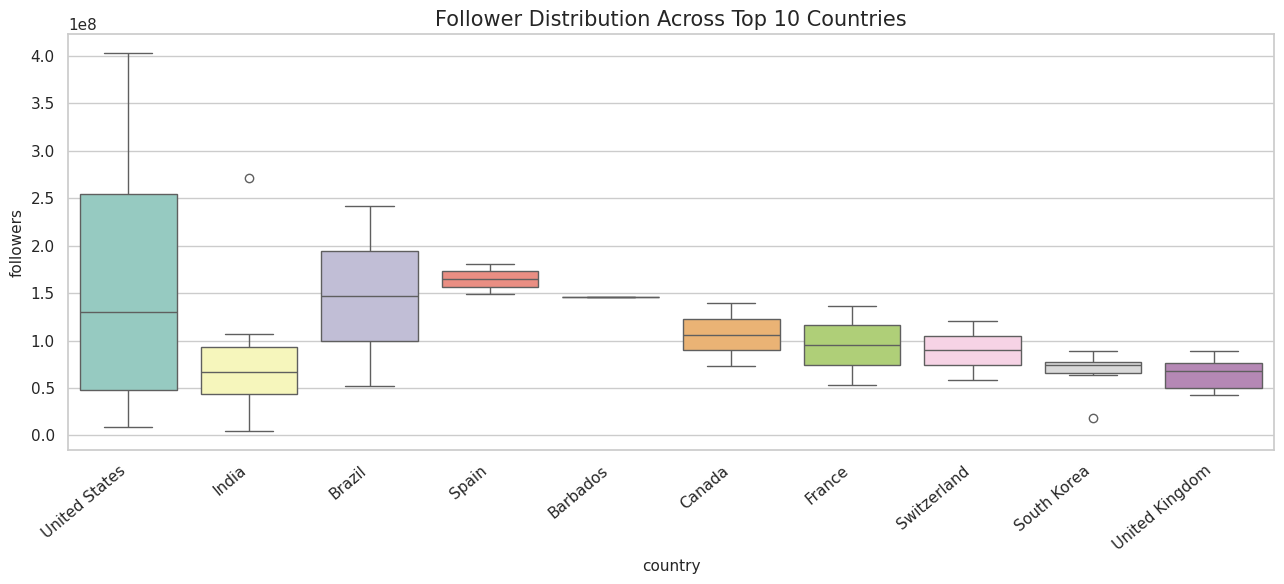

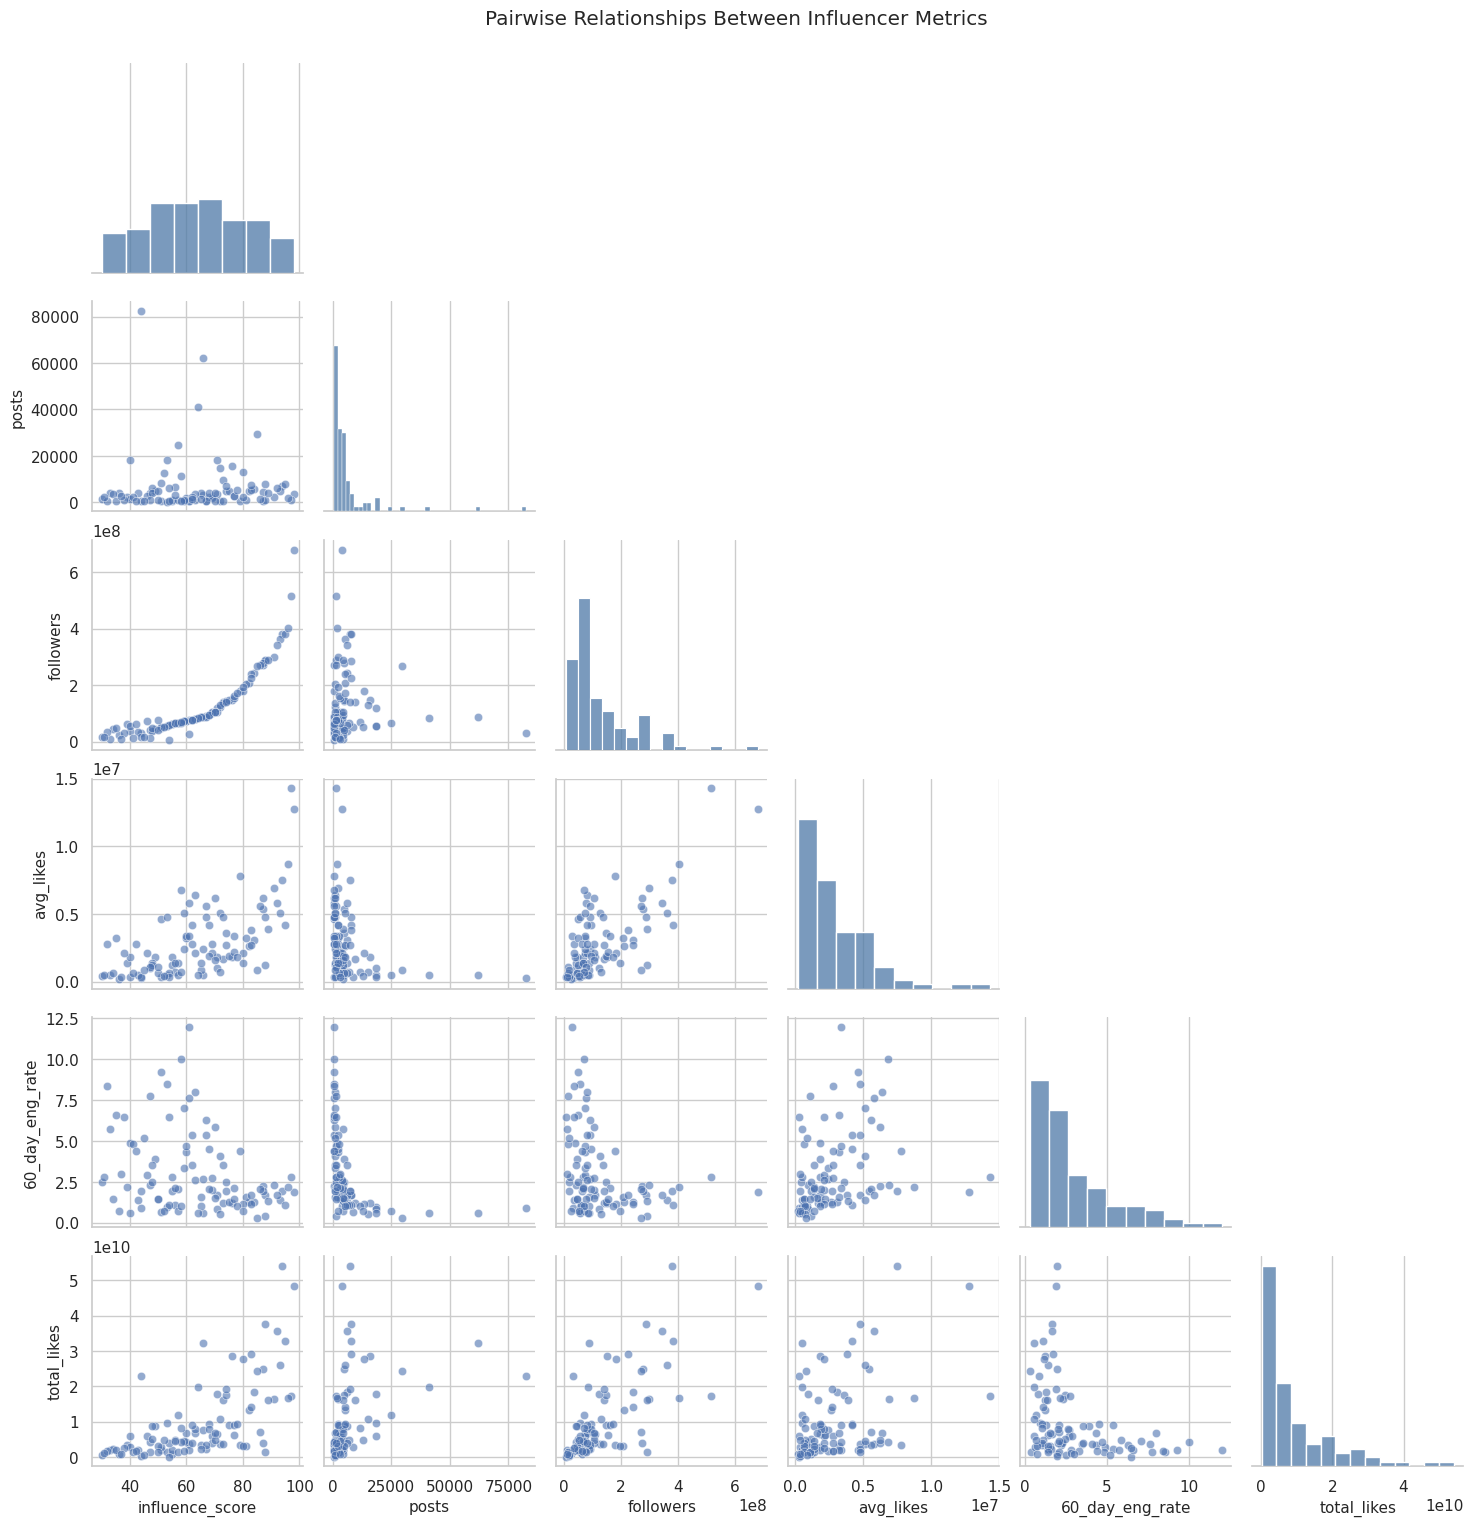

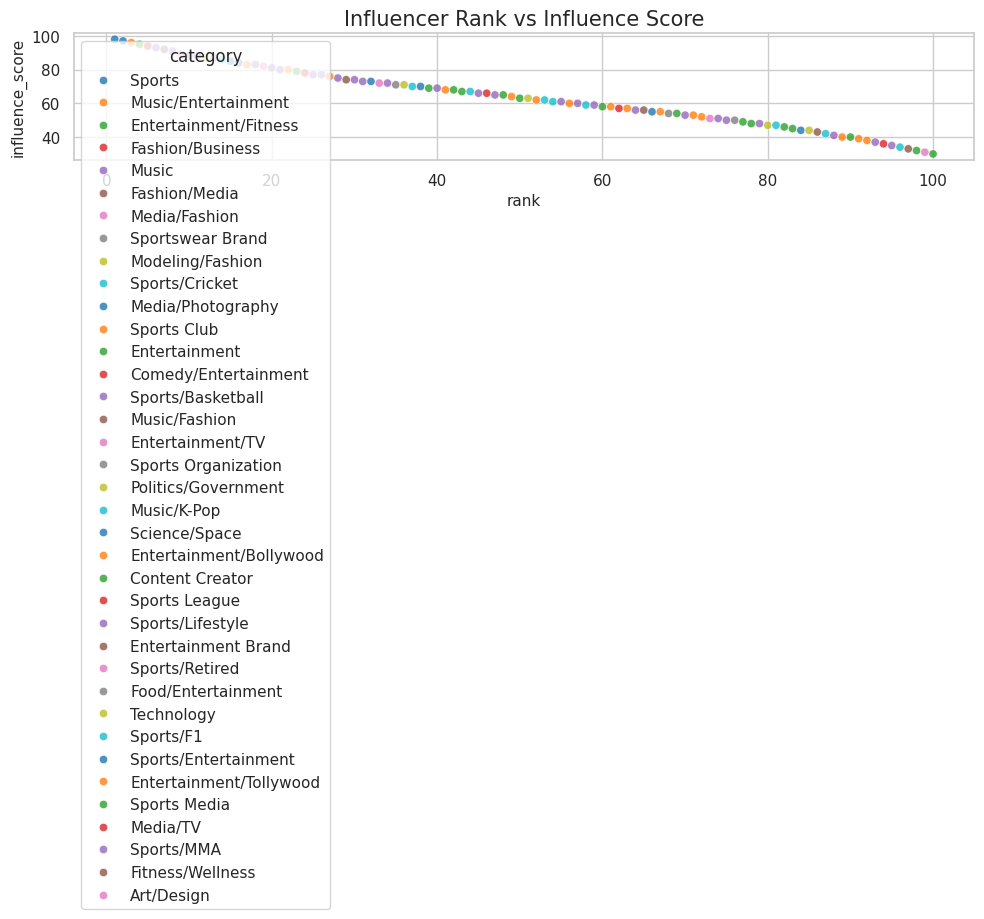

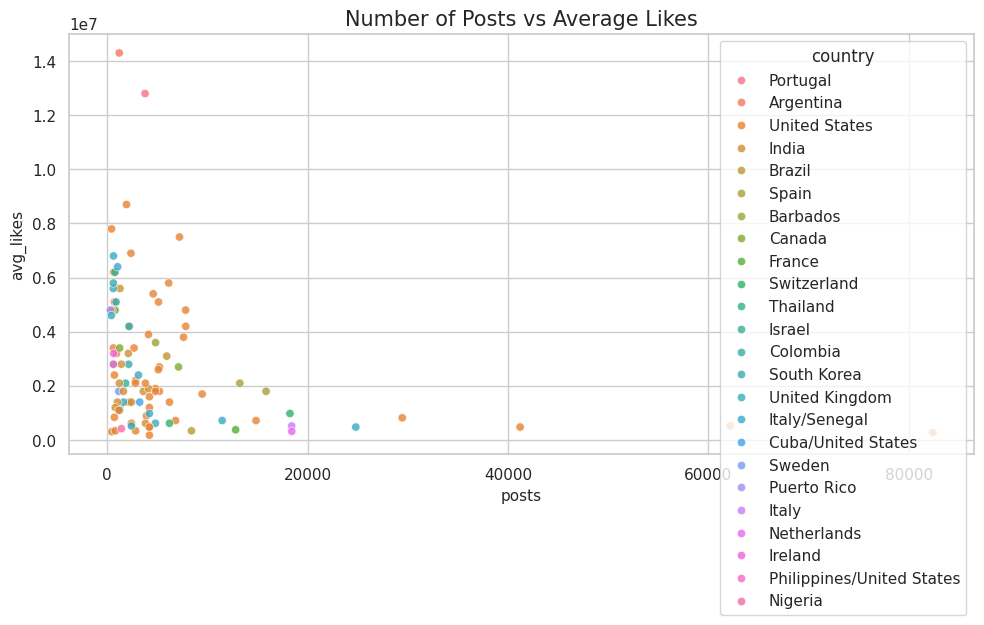

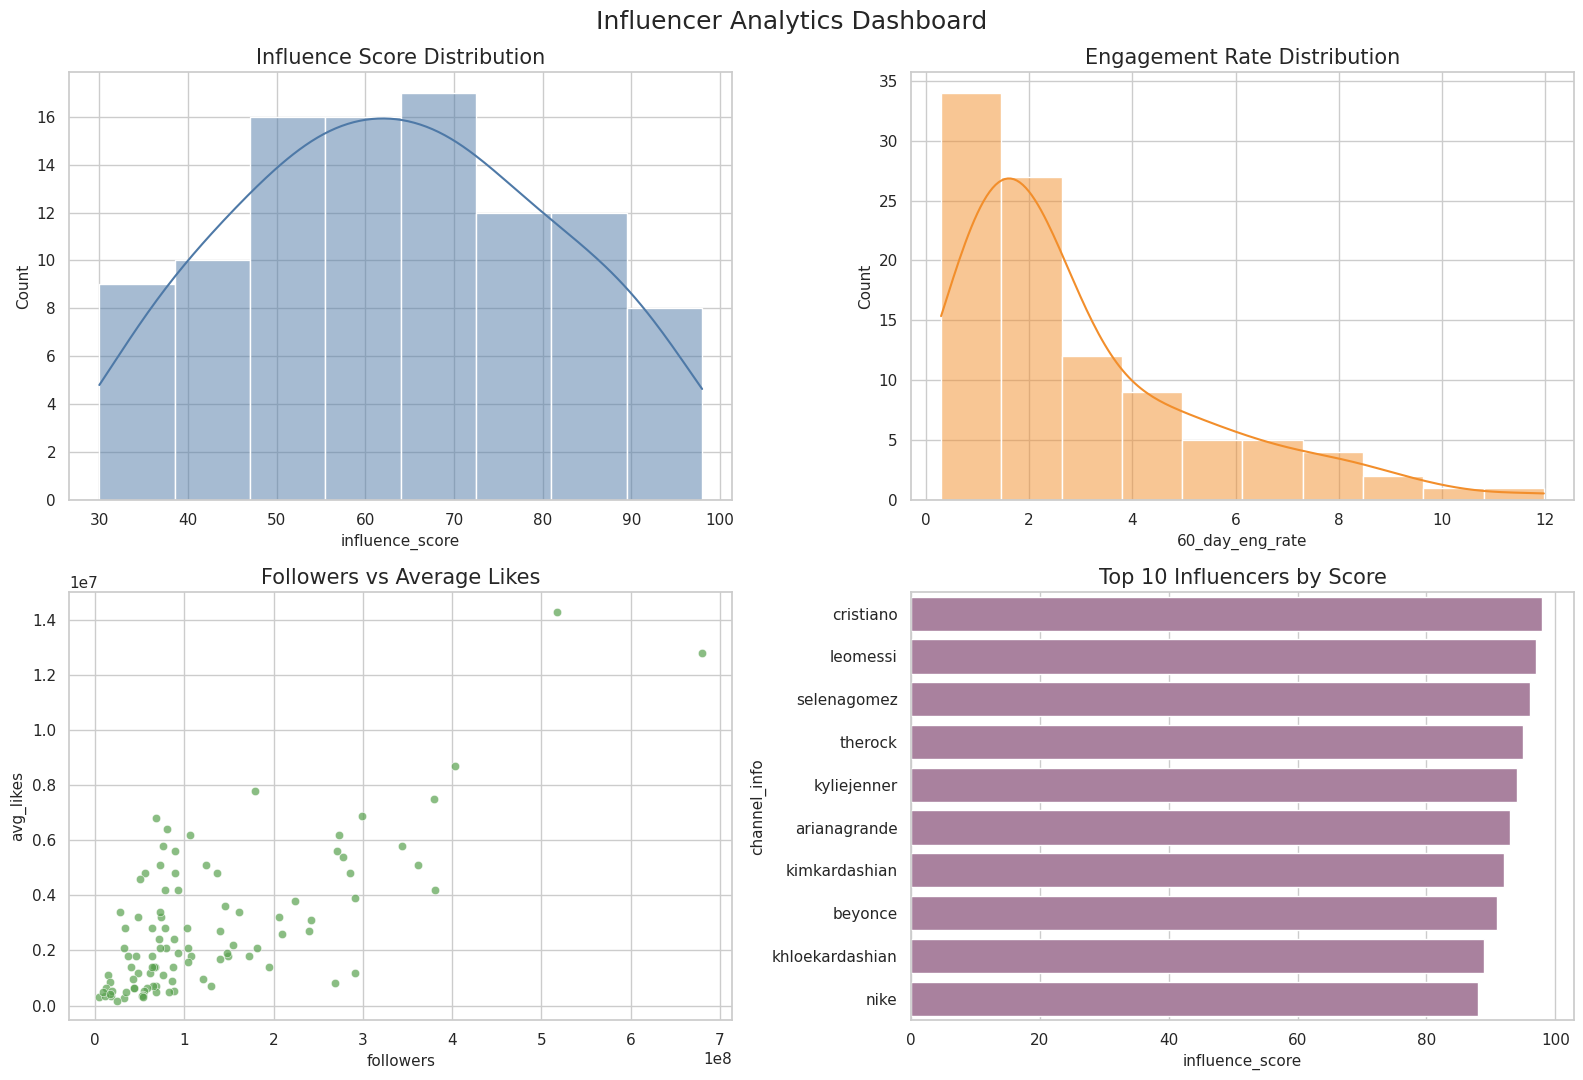


INFLUENCER DATASET - KEY SUMMARY
Total Influencers: 100
Unique Countries: 24
Unique Categories: 37

Top Influencer by Followers:
channel_info       cristiano
followers          680000000
influence_score           98
Name: 0, dtype: object

Top Influencer by Influence Score:
channel_info       cristiano
influence_score           98
followers          680000000
Name: 0, dtype: object

Highest Engagement Rate:
channel_info       postmalone
60_day_eng_rate         11.97
followers            28400000
Name: 54, dtype: object

Average Metrics:
rank                  5.050000e+01
influence_score       6.354000e+01
posts                 6.215380e+03
followers             1.257040e+08
avg_likes             2.820400e+06
60_day_eng_rate       2.960000e+00
new_post_avg_likes    3.084600e+06
total_likes           9.503970e+09
dtype: float64

Influencers by Category:
category
Music                      24
Content Creator             9
Music/K-Pop                 6
Entertainment/Bollywood     6
Sports

In [13]:

# ============================================================
# INFLUENCER DATASET - COMPLETE DATA VISUALIZATION
# Uses all available columns with different colors
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# -------------------- 1. DATA PREPARATION --------------------

# Work on a copy of the original DataFrame
df_vis = df.copy()

# Remove duplicate rows
df_vis = df_vis.drop_duplicates()

# Convert numeric columns safely
numeric_cols = [
    'rank', 'influence_score', 'posts', 'followers',
    'avg_likes', '60_day_eng_rate', 'new_post_avg_likes',
    'total_likes'
]

for col in numeric_cols:
    df_vis[col] = pd.to_numeric(df_vis[col], errors='coerce')

# Clean categorical columns
categorical_cols = ['channel_info', 'country', 'category']

for col in categorical_cols:
    df_vis[col] = df_vis[col].fillna('Unknown').astype(str).str.strip()
    df_vis[col] = df_vis[col].replace('', 'Unknown')

# Fill missing numeric values with column medians
for col in numeric_cols:
    df_vis[col] = df_vis[col].fillna(df_vis[col].median())

# Set attractive plotting defaults
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 11

print("Dataset Shape:", df_vis.shape)
print("\nDataset Information:")
df_vis.info()

print("\nStatistical Summary:")
display(df_vis.describe().T)

print("\nMissing Values:")
print(df.isnull().sum())

# -------------------- 2. MISSING VALUES --------------------

plt.figure(figsize=(12, 5))
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    sns.barplot(
        x=missing.index,
        y=missing.values,
        hue=missing.index,
        palette='viridis',
        legend=False
    )
    plt.title("Missing Values by Column")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha='right')
else:
    plt.text(0.5, 0.5, "No Missing Values",
             ha='center', va='center', fontsize=16)
    plt.title("Missing Value Analysis")

plt.tight_layout()
plt.show()

# -------------------- 3. CORRELATION HEATMAP --------------------

plt.figure(figsize=(12, 8))

corr = df_vis[numeric_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.8,
    center=0,
    square=True
)

plt.title("Correlation Heatmap of Influencer Metrics")
plt.tight_layout()
plt.show()

# -------------------- 4. NUMERIC DISTRIBUTIONS --------------------

colors = [
    '#FF6B6B', '#4E79A7', '#59A14F', '#F28E2B',
    '#B07AA1', '#76B7B2', '#EDC948', '#E15759'
]

for i, col in enumerate(numeric_cols):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.histplot(
        data=df_vis, x=col, kde=True,
        color=colors[i], ax=axes[0]
    )
    axes[0].set_title(f'Distribution of {col}')

    sns.boxplot(
        data=df_vis, x=col,
        color=colors[(i + 1) % len(colors)],
        ax=axes[1]
    )
    axes[1].set_title(f'Outlier Analysis: {col}')

    plt.tight_layout()
    plt.show()

# -------------------- 5. TOP 10 INFLUENCERS BY FOLLOWERS --------------------

top_followers = df_vis.nlargest(10, 'followers').sort_values('followers')

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_followers,
    x='followers',
    y='channel_info',
    hue='followers',
    palette='viridis',
    legend=False
)
plt.title("Top 10 Influencers by Followers")
plt.xlabel("Followers")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()

# -------------------- 6. TOP 10 BY INFLUENCE SCORE --------------------

top_influence = df_vis.nlargest(10, 'influence_score').sort_values(
    'influence_score'
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_influence,
    x='influence_score',
    y='channel_info',
    hue='influence_score',
    palette='magma',
    legend=False
)
plt.title("Top 10 Influencers by Influence Score")
plt.tight_layout()
plt.show()

# -------------------- 7. TOP 10 BY TOTAL LIKES --------------------

top_likes = df_vis.nlargest(10, 'total_likes').sort_values('total_likes')

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_likes,
    x='total_likes',
    y='channel_info',
    hue='total_likes',
    palette='rocket',
    legend=False
)
plt.title("Top 10 Influencers by Total Likes")
plt.tight_layout()
plt.show()

# -------------------- 8. TOP 10 BY AVERAGE LIKES --------------------

top_avg_likes = df_vis.nlargest(10, 'avg_likes').sort_values('avg_likes')

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_avg_likes,
    x='avg_likes',
    y='channel_info',
    hue='avg_likes',
    palette='crest',
    legend=False
)
plt.title("Top 10 Influencers by Average Likes")
plt.tight_layout()
plt.show()

# -------------------- 9. ENGAGEMENT RATE ANALYSIS --------------------

top_engagement = df_vis.nlargest(10, '60_day_eng_rate').sort_values(
    '60_day_eng_rate'
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_engagement,
    x='60_day_eng_rate',
    y='channel_info',
    hue='60_day_eng_rate',
    palette='flare',
    legend=False
)
plt.title("Top 10 Influencers by 60-Day Engagement Rate")
plt.xlabel("60-Day Engagement Rate")
plt.tight_layout()
plt.show()

# -------------------- 10. POSTS VS FOLLOWERS --------------------

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df_vis,
    x='posts',
    y='followers',
    hue='influence_score',
    size='avg_likes',
    sizes=(30, 250),
    palette='viridis',
    alpha=0.75
)
plt.title("Posts vs Followers (Color = Influence Score)")
plt.tight_layout()
plt.show()

# -------------------- 11. FOLLOWERS VS TOTAL LIKES --------------------

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df_vis,
    x='followers',
    y='total_likes',
    hue='category',
    palette='tab10',
    alpha=0.8
)
plt.title("Followers vs Total Likes by Category")
plt.tight_layout()
plt.show()

# -------------------- 12. ENGAGEMENT VS INFLUENCE --------------------

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df_vis,
    x='60_day_eng_rate',
    y='influence_score',
    hue='country',
    palette='husl',
    alpha=0.8
)
plt.title("Engagement Rate vs Influence Score by Country")
plt.tight_layout()
plt.show()

# -------------------- 13. AVERAGE LIKES VS NEW POST LIKES --------------------

plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_vis,
    x='avg_likes',
    y='new_post_avg_likes',
    scatter_kws={'alpha': 0.6, 'color': '#4E79A7'},
    line_kws={'color': '#E15759'}
)
plt.title("Average Likes vs New Post Average Likes")
plt.tight_layout()
plt.show()

# -------------------- 14. CATEGORY DISTRIBUTION --------------------

category_counts = df_vis['category'].value_counts().head(12)

plt.figure(figsize=(10, 7))
plt.pie(
    category_counts.values,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('Set3', len(category_counts))
)
plt.title("Influencer Distribution by Category (Top 12)")
plt.tight_layout()
plt.show()

# -------------------- 15. COUNTRY DISTRIBUTION --------------------

country_counts = df_vis['country'].value_counts().head(15)

plt.figure(figsize=(12, 7))
sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    hue=country_counts.index,
    palette='Spectral',
    legend=False
)
plt.title("Top 15 Countries by Influencer Count")
plt.xlabel("Number of Influencers")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

# -------------------- 16. ENGAGEMENT BY CATEGORY --------------------

top_categories = df_vis['category'].value_counts().head(10).index
category_data = df_vis[df_vis['category'].isin(top_categories)]

plt.figure(figsize=(13, 6))
sns.boxplot(
    data=category_data,
    x='category',
    y='60_day_eng_rate',
    hue='category',
    palette='Set2',
    legend=False
)
plt.title("Engagement Rate Distribution by Category")
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

# -------------------- 17. INFLUENCE SCORE BY CATEGORY --------------------

plt.figure(figsize=(13, 6))
sns.barplot(
    data=category_data,
    x='category',
    y='influence_score',
    hue='category',
    palette='Paired',
    errorbar=None,
    legend=False
)
plt.title("Average Influence Score by Category")
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

# -------------------- 18. FOLLOWERS BY COUNTRY --------------------

top_countries = df_vis['country'].value_counts().head(10).index
country_data = df_vis[df_vis['country'].isin(top_countries)]

plt.figure(figsize=(13, 6))
sns.boxplot(
    data=country_data,
    x='country',
    y='followers',
    hue='country',
    palette='Set3',
    legend=False
)
plt.title("Follower Distribution Across Top 10 Countries")
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

# -------------------- 19. PAIRWISE NUMERIC RELATIONSHIPS --------------------

pair_cols = [
    'influence_score', 'posts', 'followers',
    'avg_likes', '60_day_eng_rate', 'total_likes'
]

# Sample rows if the dataset is large
pair_data = df_vis[pair_cols].sample(
    n=min(500, len(df_vis)),
    random_state=42
)

sns.pairplot(
    pair_data,
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.6},
    diag_kws={'color': '#4E79A7'}
)
plt.suptitle("Pairwise Relationships Between Influencer Metrics", y=1.02)
plt.show()

# -------------------- 20. RANK VS INFLUENCE SCORE --------------------

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_vis,
    x='rank',
    y='influence_score',
    hue='category',
    palette='tab10',
    alpha=0.8
)
plt.title("Influencer Rank vs Influence Score")
plt.tight_layout()
plt.show()

# -------------------- 21. POSTS VS AVERAGE LIKES --------------------

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_vis,
    x='posts',
    y='avg_likes',
    hue='country',
    palette='husl',
    alpha=0.8
)
plt.title("Number of Posts vs Average Likes")
plt.tight_layout()
plt.show()

# -------------------- 22. SUMMARY DASHBOARD --------------------

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.histplot(
    data=df_vis, x='influence_score',
    kde=True, color='#4E79A7', ax=axes[0, 0]
)
axes[0, 0].set_title("Influence Score Distribution")

sns.histplot(
    data=df_vis, x='60_day_eng_rate',
    kde=True, color='#F28E2B', ax=axes[0, 1]
)
axes[0, 1].set_title("Engagement Rate Distribution")

sns.scatterplot(
    data=df_vis, x='followers', y='avg_likes',
    color='#59A14F', alpha=0.7, ax=axes[1, 0]
)
axes[1, 0].set_title("Followers vs Average Likes")

sns.barplot(
    data=df_vis.nlargest(10, 'influence_score'),
    x='influence_score', y='channel_info',
    color='#B07AA1', ax=axes[1, 1]
)
axes[1, 1].set_title("Top 10 Influencers by Score")

plt.suptitle("Influencer Analytics Dashboard", fontsize=18)
plt.tight_layout()
plt.show()

# -------------------- 23. FINAL INSIGHTS --------------------

print("\n" + "=" * 60)
print("INFLUENCER DATASET - KEY SUMMARY")
print("=" * 60)

print("Total Influencers:", len(df_vis))
print("Unique Countries:", df_vis['country'].nunique())
print("Unique Categories:", df_vis['category'].nunique())

print("\nTop Influencer by Followers:")
print(
    df_vis.loc[df_vis['followers'].idxmax(),
               ['channel_info', 'followers', 'influence_score']]
)

print("\nTop Influencer by Influence Score:")
print(
    df_vis.loc[df_vis['influence_score'].idxmax(),
               ['channel_info', 'influence_score', 'followers']]
)

print("\nHighest Engagement Rate:")
print(
    df_vis.loc[df_vis['60_day_eng_rate'].idxmax(),
               ['channel_info', '60_day_eng_rate', 'followers']]
)

print("\nAverage Metrics:")
print(df_vis[numeric_cols].mean().round(2))

print("\nInfluencers by Category:")
print(df_vis['category'].value_counts().head(10))

print("\nInfluencers by Country:")
print(df_vis['country'].value_counts().head(10))

print("\nVisualization Completed Successfully!")


## Feature engineering

Influence score median threshold: 63.0

Target distribution:
Influence_Level
High Influence    51
Low Influence     49
Name: count, dtype: int64

Training data shape: (80, 8)
Testing data shape: (20, 8)

Label Encoding Completed

country encoding:
{'Barbados': 0, 'Brazil': 1, 'Canada': 2, 'Colombia': 3, 'Cuba/United States': 4, 'France': 5, 'India': 6, 'Ireland': 7, 'Israel': 8, 'Italy': 9, 'Italy/Senegal': 10, 'Philippines/United States': 11, 'Portugal': 12, 'South Korea': 13, 'Spain': 14, 'Switzerland': 15, 'Thailand': 16, 'United Kingdom': 17, 'United States': 18}

category encoding:
{'Art/Design': 0, 'Comedy/Entertainment': 1, 'Content Creator': 2, 'Entertainment': 3, 'Entertainment Brand': 4, 'Entertainment/Bollywood': 5, 'Entertainment/Fitness': 6, 'Entertainment/TV': 7, 'Entertainment/Tollywood': 8, 'Fashion/Business': 9, 'Fitness/Wellness': 10, 'Food/Entertainment': 11, 'Media/Fashion': 12, 'Media/Photography': 13, 'Modeling/Fashion': 14, 'Music': 15, 'Music/Entertainment': 16,

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC (%)
0,Logistic Regression,100.0,100.0,100.0,100.00,100.0
1,Decision Tree,100.0,100.0,100.0,100.00,100.0
2,Random Forest,100.0,100.0,100.0,100.00,100.0
3,Gradient Boosting,100.0,100.0,100.0,100.00,100.0
4,Gaussian Naive Bayes,100.0,100.0,100.0,100.00,100.0
5,Support Vector Machine,95.0,100.0,90.0,94.74,99.0
6,K-Nearest Neighbors,90.0,100.0,80.0,88.89,96.0


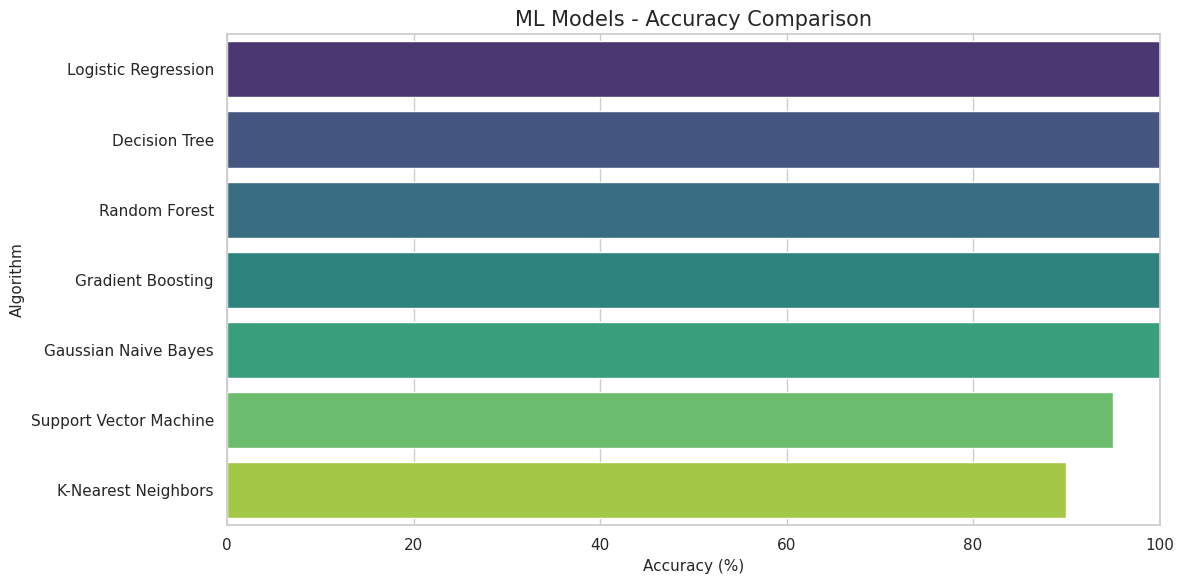

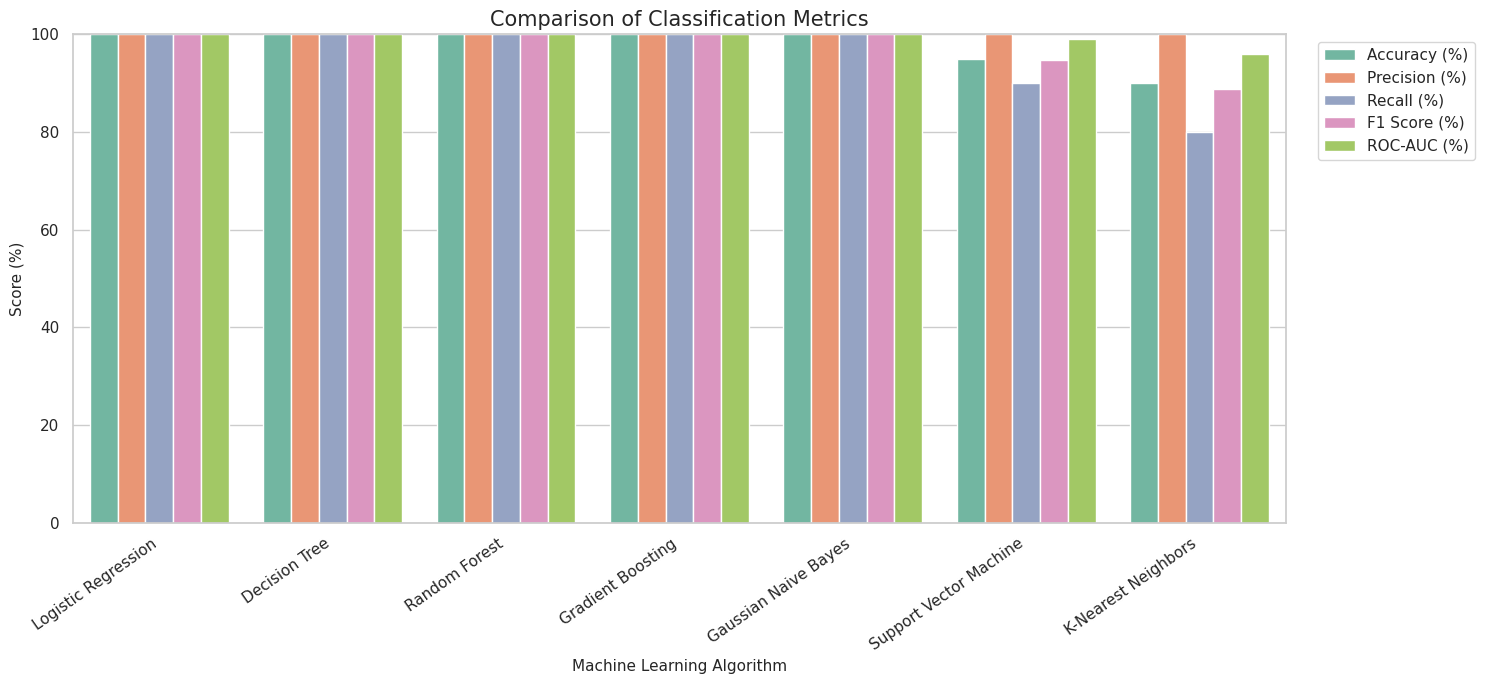

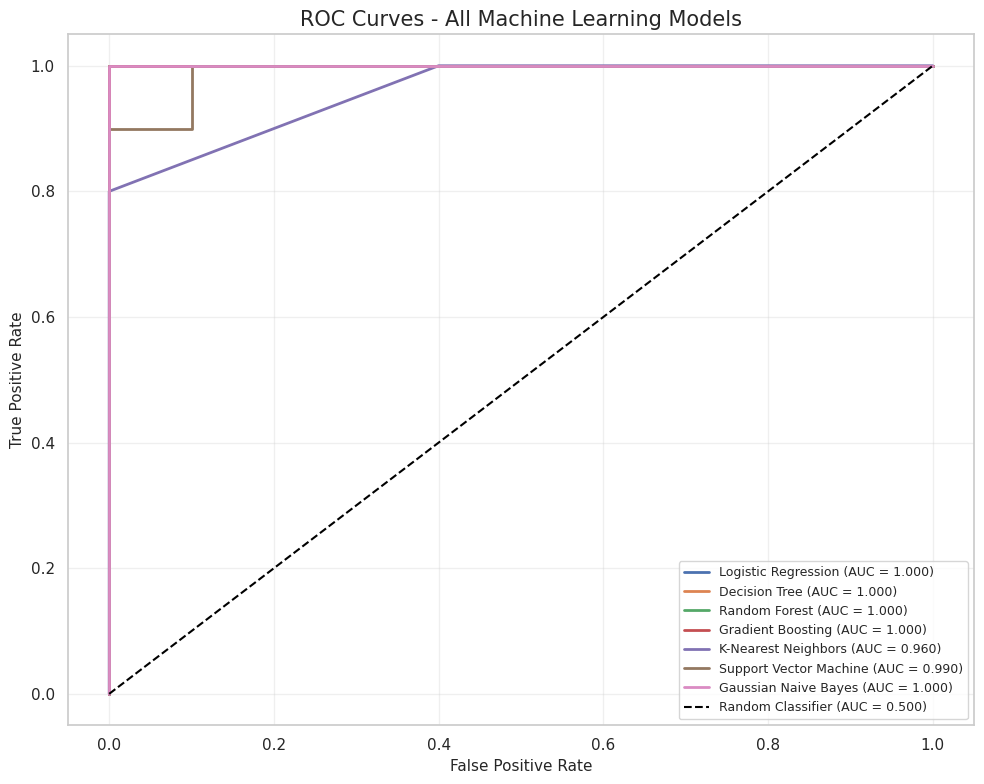

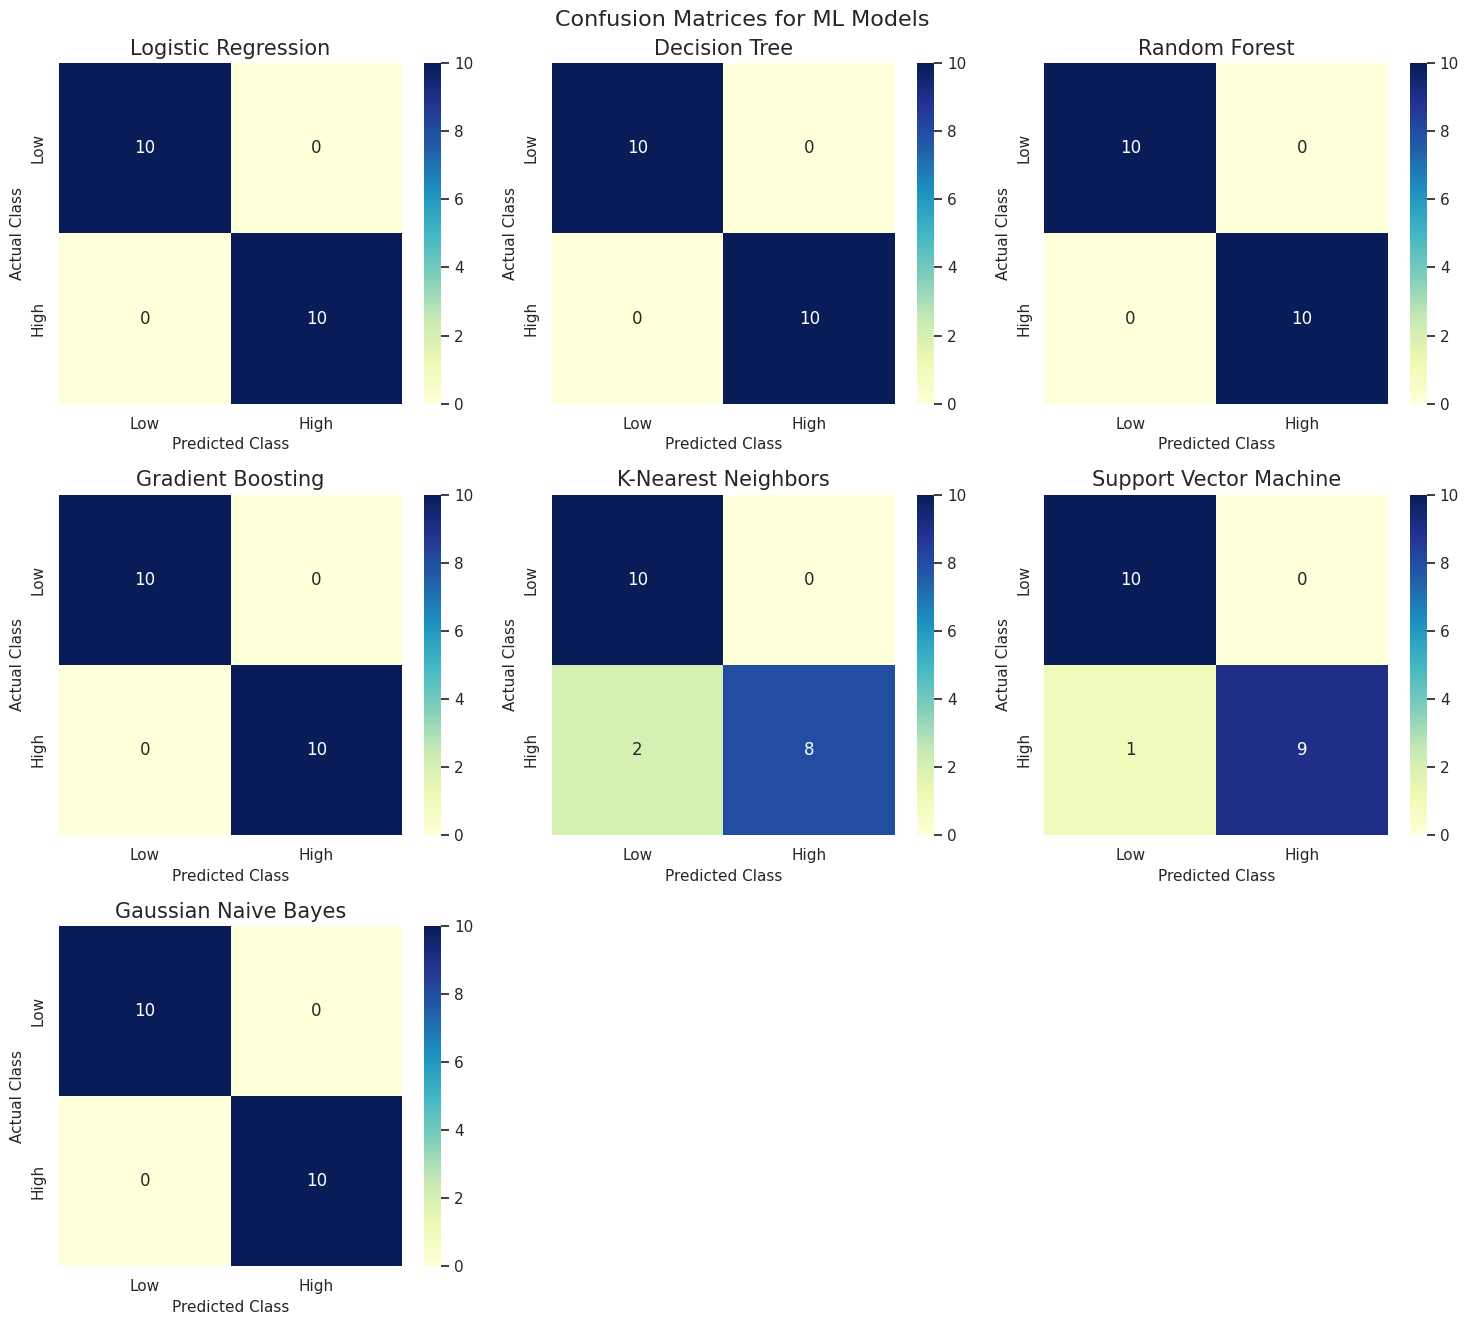


BEST MODEL BASED ON ROC-AUC
Best Algorithm: Logistic Regression
ROC-AUC: 100.00%
Accuracy: 100.00%

Best Model Confusion Matrix:
[[10  0]
 [ 0 10]]

Best Model Classification Report:
                precision    recall  f1-score   support

 Low Influence       1.00      1.00      1.00        10
High Influence       1.00      1.00      1.00        10

      accuracy                           1.00        20
     macro avg       1.00      1.00      1.00        20
  weighted avg       1.00      1.00      1.00        20


Machine Learning Pipeline Completed Successfully!


In [14]:

# ==============================================================
# INFLUENCER DATASET: COMPLETE MACHINE LEARNING PIPELINE
# Train-Test Split + Label Encoding + Multiple ML Algorithms
# Accuracy + Classification Report + Confusion Matrix + ROC Curve
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# -------------------- 1. DATA PREPARATION --------------------

df_ml = df.copy()
df_ml = df_ml.drop_duplicates().reset_index(drop=True)

numeric_cols = [
    'rank', 'influence_score', 'posts', 'followers',
    'avg_likes', '60_day_eng_rate',
    'new_post_avg_likes', 'total_likes'
]

categorical_cols = ['country', 'category']

# Convert numeric columns to numbers
for col in numeric_cols:
    df_ml[col] = pd.to_numeric(df_ml[col], errors='coerce')

# Remove rows where the target cannot be calculated
df_ml = df_ml.dropna(subset=['influence_score']).copy()

# Fill missing categorical values
for col in categorical_cols:
    df_ml[col] = df_ml[col].fillna('Unknown').astype(str).str.strip()
    df_ml[col] = df_ml[col].replace('', 'Unknown')

# -------------------- 2. CREATE TARGET VARIABLE --------------------
# Existing influence_score is used to define the target.
# High Influence = score >= median
# Low Influence  = score < median
#
# IMPORTANT: influence_score and rank are excluded from features
# to reduce direct target leakage.

threshold = df_ml['influence_score'].median()

df_ml['Influence_Level'] = np.where(
    df_ml['influence_score'] >= threshold,
    'High Influence',
    'Low Influence'
)

print("Influence score median threshold:", threshold)
print("\nTarget distribution:")
print(df_ml['Influence_Level'].value_counts())

# -------------------- 3. SELECT FEATURES --------------------

# Exclude influence_score because it defines the target.
# Exclude rank as it may directly reflect influencer ranking.
# Exclude channel_info because it is an identifier-like column.

feature_cols = [
    'posts',
    'followers',
    'avg_likes',
    '60_day_eng_rate',
    'new_post_avg_likes',
    'total_likes',
    'country',
    'category'
]

X = df_ml[feature_cols].copy()
y = df_ml['Influence_Level'].map({
    'Low Influence': 0,
    'High Influence': 1
})

# -------------------- 4. TRAIN-TEST SPLIT --------------------

# 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# -------------------- 5. LABEL ENCODING --------------------

# Fit encoders only on the training set.
# Unknown test categories receive code -1.

encoders = {}

for col in categorical_cols:
    le = LabelEncoder()

    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

    X_train[col] = le.fit_transform(X_train[col])

    mapping = {
        label: index
        for index, label in enumerate(le.classes_)
    }

    X_test[col] = X_test[col].map(mapping).fillna(-1).astype(int)

    encoders[col] = le

print("\nLabel Encoding Completed")
for col, le in encoders.items():
    print(f"\n{col} encoding:")
    print({label: i for i, label in enumerate(le.classes_)})

# Ensure numeric columns are numeric
X_train = X_train.apply(pd.to_numeric, errors='coerce')
X_test = X_test.apply(pd.to_numeric, errors='coerce')

# -------------------- 6. DEFINE ML ALGORITHMS --------------------

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000, class_weight='balanced'
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=8, random_state=42, class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=12,
        random_state=42, n_jobs=-1,
        class_weight='balanced'
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1,
        max_depth=3, random_state=42
    ),

    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Support Vector Machine': SVC(
        kernel='rbf', probability=True,
        class_weight='balanced', random_state=42
    ),

    'Gaussian Naive Bayes': GaussianNB()
}

# -------------------- 7. TRAIN, PREDICT AND EVALUATE --------------------

results = []
trained_models = {}
roc_data = {}
predictions = {}

for name, model in models.items():

    print("\n" + "=" * 65)
    print("MODEL:", name)
    print("=" * 65)

    # Imputation and scaling are learned only from training data.
    # Scaling particularly helps Logistic Regression, KNN and SVM.
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', model)
    ])

    try:
        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)[:, 1]

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred, zero_division=0
        )
        recall = recall_score(
            y_test, y_pred, zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )
        roc_auc = roc_auc_score(y_test, y_prob)

        results.append({
            'Model': name,
            'Accuracy (%)': accuracy * 100,
            'Precision (%)': precision * 100,
            'Recall (%)': recall * 100,
            'F1 Score (%)': f1 * 100,
            'ROC-AUC (%)': roc_auc * 100
        })

        trained_models[name] = pipeline
        predictions[name] = y_pred

        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_data[name] = (fpr, tpr, roc_auc)

        print(f"Accuracy:  {accuracy * 100:.2f}%")
        print(f"Precision: {precision * 100:.2f}%")
        print(f"Recall:    {recall * 100:.2f}%")
        print(f"F1 Score:  {f1 * 100:.2f}%")
        print(f"ROC-AUC:   {roc_auc * 100:.2f}%")

        print("\nClassification Report:")
        print(classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=['Low Influence', 'High Influence'],
            zero_division=0
        ))

    except Exception as e:
        print(f"Model failed: {e}")

# -------------------- 8. MODEL COMPARISON --------------------

results_df = pd.DataFrame(results)

if results_df.empty:
    raise ValueError(
        "No models trained successfully. Check your target classes "
        "and input data."
    )

results_df = results_df.sort_values(
    by='ROC-AUC (%)', ascending=False
).reset_index(drop=True)

print("\n\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(2))

# -------------------- 9. MODEL ACCURACY COMPARISON --------------------

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Accuracy (%)',
    y='Model',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('ML Models - Accuracy Comparison')
plt.xlabel('Accuracy (%)')
plt.ylabel('Algorithm')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# -------------------- 10. COMPARE ALL EVALUATION METRICS --------------------

metrics_to_plot = [
    'Accuracy (%)', 'Precision (%)',
    'Recall (%)', 'F1 Score (%)', 'ROC-AUC (%)'
]

results_long = results_df.melt(
    id_vars='Model',
    value_vars=metrics_to_plot,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=results_long,
    x='Model',
    y='Score',
    hue='Metric',
    palette='Set2'
)

plt.title('Comparison of Classification Metrics')
plt.ylabel('Score (%)')
plt.xlabel('Machine Learning Algorithm')
plt.xticks(rotation=35, ha='right')
plt.ylim(0, 100)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# -------------------- 11. ROC CURVE FOR ALL MODELS --------------------

plt.figure(figsize=(10, 8))

for name, (fpr, tpr, roc_auc) in roc_data.items():
    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f'{name} (AUC = {roc_auc:.3f})'
    )

# Random classifier reference line
plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='black',
    linewidth=1.5,
    label='Random Classifier (AUC = 0.500)'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Machine Learning Models')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------- 12. CONFUSION MATRICES --------------------

n_models = len(trained_models)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 4.5 * n_rows)
)

axes = np.array(axes).reshape(-1)

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='YlGnBu',
        xticklabels=['Low', 'High'],
        yticklabels=['Low', 'High'],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted Class')
    axes[i].set_ylabel('Actual Class')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Confusion Matrices for ML Models', fontsize=16)
plt.tight_layout()
plt.show()

# -------------------- 13. BEST MODEL SUMMARY --------------------

best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
best_pred = predictions[best_model_name]

print("\n" + "=" * 65)
print("BEST MODEL BASED ON ROC-AUC")
print("=" * 65)

print("Best Algorithm:", best_model_name)
print(
    "ROC-AUC:",
    f"{results_df.iloc[0]['ROC-AUC (%)']:.2f}%"
)
print(
    "Accuracy:",
    f"{results_df.iloc[0]['Accuracy (%)']:.2f}%"
)

print("\nBest Model Confusion Matrix:")
print(confusion_matrix(y_test, best_pred, labels=[0, 1]))

print("\nBest Model Classification Report:")
print(classification_report(
    y_test,
    best_pred,
    labels=[0, 1],
    target_names=['Low Influence', 'High Influence'],
    zero_division=0
))

print("\nMachine Learning Pipeline Completed Successfully!")

## Thank you..pls upvote!!!!!!